# Fair test of Gemma's BFS steering dial (claim G, iteration 8)

**The question.** Ask `gemma-3-4b-it` to *"write a Python function `solve(grid, start, goal)` that finds a path between
two cells of a grid"* and it usually writes a **depth-first search** (DFS). **Breadth-first search** (BFS) is the
minority answer. In the previous iteration, a rank-4 subspace of the residual stream at decoder block 17, found with
distributed alignment search (DAS), worked like a **dial**: setting its coordinates to the "BFS" class mean at the fork
token raised correct BFS programs from 11/50 to 42/50. This experiment asks whether that dial actually beats
**just asking for BFS in the prompt**, under a fair comparison.

**The fork.** Gemma's usual answer starts with the same 32 tokens, called **c\***: the python code fence, the
`def solve(grid, start, goal):` line, `rows = len(grid)`, `cols = len(grid[0])` and the body indent. The next token
(response token 32) decides the algorithm: `' visited'` leads to DFS, while `'\n'`, `'if'`, `' queue'` or `'q'` lead to BFS.

**The design.** Every condition (a *cell*) samples one program for each of the same **50 common-random-number (CRN)
slots**: 5 prompt templates W1-W5 times 10 random streams. Cells are therefore paired slot by slot. The headline 2x2 is
{forced-BFS prompt, DAS dial} x {c\* prefilled, free generation}. Labels come from 48 hidden tests and a BFS/DFS
classifier. "Correct BFS" means the program is BFS *and* passes every test.

**Recorded findings** (RTX 4090, 1,320 programs, hash-chained commitments #0-#4 written before each batch of samples):
1. **Prompting collapses when the c\* prefix is forced.** With the forced-BFS prompt plus c\*, all 50/50 programs are
   BFS but **0/50 are correct**. The fork token becomes `' queue'`, and those list-based BFS programs skip the
   start/goal wall check. The dial gets **39/50** (39/0 discordant pairs, exact McNemar p = 3.6e-12).
2. **The dial also works in free generation.** With the edit placed at a decision position fixed in advance, it gets
   **38/50** correct BFS against 13/50 for the unedited free twin (p = 2.1e-7).
3. **In free generation the dial does not beat prompting.** The forced-BFS prompt gets 32/50 (p = 0.21 against the
   dial). The best of 8 prompt wordings reaches **49/50**. The interaction between dial and prefill is 0.66 [0.50, 0.82].
4. **The subspace is dormant.** It holds little of the natural variance of the twin states: it is an off-manifold
   handle, not a direction the model uses on its own.

**What runs here.** `method.py` is a staged pipeline. Its sampling stages need the 4B model on a CUDA GPU (about 14
GPU-minutes on an RTX 4090; the whole pipeline takes about 45 minutes), and the model is gated on the Hub. The notebook shows that code **unchanged** but executes only the CPU
parts, using the recorded outputs in `mini_demo_data.json`:

| `method.py` part | in this notebook |
|---|---|
| S0 checker gate (5 hand-made wrong programs must fail the hidden tests) | **runs live** |
| GPU stages `gpu1`, `commit2`, `fcells`, `gpu_extra`, `tf_extra` | code shown, not executed; recorded outputs replayed |
| commit #2 decision-position rule and its predictions | **runs live** on the recorded free-twin token traces |
| label stage (hidden tests and BFS/DFS classifier) | **runs live** on 8 cells' raw model text |
| analysis stage (McNemar, Holm, Newcombe, bootstrap, scorecard P1-P6) | **runs live** |
| block-17 geometry of the dial (DAS / DiM edits, agreement across seeds) | **runs live** in numpy |

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT pre-installed on Colab (method.py logs through it), always install
_pip('loguru==0.7.3')

# numpy, scipy, matplotlib — pre-installed on Colab, install locally only (Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

import argparse
import json
import sys
import time
from pathlib import Path
from typing import Any

from loguru import logger  # noqa: E402

# ---- added for the notebook (method.py gets these through its src/ modules, inlined further down)
import base64
import hashlib
import math
import os
import random
import re
import resource
import subprocess
import types
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
from datetime import datetime, timezone
from typing import Callable, Iterable

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import binomtest

logger.remove()
_ = logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_jSassd-YWLVC/round-8/experiment-42/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
META, EXAMPLES = data["metadata"], data["examples"]
EX = {e["slot_id"]: e for e in EXAMPLES}          # 'W1|0' -> one CRN slot
print(META["title"])
print(f"{len(EXAMPLES)} CRN slots, {len(META['cells'])} cells; model: {META['model']}")
print("per slot: labels of every cell, raw text of", list(META["rescore_cells"]))
print("          + the free twin's first 97 tokens with p_B / p_D, the committed decision, the block-17 state")

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
Fair test of Gemma's BFS steering dial (claim G, iteration 8) - demo subset
50 CRN slots, 26 cells; model: google/gemma-3-4b-it, bf16, one RTX 4090; T = 1.0, top-p 1, no top-k, max_new 1024
per slot: labels of every cell, raw text of ['P-twin', 'G1a', 'P-DAS-bfs', 'F-twin', 'G1c', 'F-DAS-r4-bfs-1.0', 'F-DiM-bfs', 'G1e|F3|3']
          + the free twin's first 97 tokens with p_B / p_D, the committed decision, the block-17 state


## Configuration

Every tunable quantity of the CPU replay. The values below are the ones this notebook ships with. The original
values are in the comments; with them the whole notebook runs in a few minutes on two CPU cores. The GPU stages have
their own sizes (B_CRN 25, max_new 1024, 50 slots per cell). Those are fixed in `cfg8` and are not re-run here.

In [5]:
# ---- demo scale (original values in the comments)
N_SLOTS = 50         # CRN slots (of the 50 in S50) replayed live: decision rule + label stage   (original: 50)
N_WORKERS = 2        # parallel hidden-test subprocesses; keep <= CPU count (per-case limits are wall-clock)  (original: 12, 14-CPU box)
N_PLACEBO = 1000     # within-slot label-swap placebos per paired test (audit/rederive_raw.py)    (original: 1000)
N_BOOT_SLOTS = 10000 # slot-bootstrap resamples of the 2x2 interaction (cfg8.N_BOOT_SLOTS)         (original: 10000)
N_HILL_REP = 1000    # rarefaction repeats of the Hill-1 diversity of correct programs           (original: 1000)
N_HAAR = 1000        # random (Haar) rank-k subspaces in the geometry null                       (original: 1000, cfg8.N_HAAR_VAR)

## Constants and helpers from `src/cfg.py` and `src/cfg8.py`

`method.py` imports its constants and small utilities from `src/`. They are inlined here unchanged, with three
exceptions: `ROOT` is the working directory, the loop that creates output folders is dropped (this notebook writes
nothing to disk), and `N_BOOT_SLOTS` comes from the config cell. Key definitions:

- **B** = {`'\n'` 107, `'if'` 584, `' queue'` 15204, `'q'` 236809} and **D** = {`' visited'` 53227} are the fork-token
  classes. The fork margin is m = logsumexp(z[B]) - z[visited].
- **Twin prompts** W1-W5 are the five "Do not use {X}" templates with a neutral noun in place of an algorithm name
  ("Do not use house for this task."). **Forced prompts** F1-F5 say "Use {Y}" with Y = BFS or DFS.
- **S50** = {(w, k): w in W1-W5, k in 0-9}. **S30** is its k < 6 part. The `ukey` of a slot picks its uniform stream.

In [6]:
# ---- src/cfg.py: paths, model, fork classes, templates, design constants
ROOT = Path.cwd()                                # was: Path(__file__).resolve().parents[1]
I6 = ROOT / "inputs" / "iter6_gemma"            # read-only copy of the iteration-6 Gemma artifact (MANIFEST.sha256)
INPUTS = I6 / "inputs"
E8 = INPUTS / "exp8"
E11 = INPUTS / "exp11"
E7 = INPUTS / "exp7"
E9 = INPUTS / "exp9"
E23 = INPUTS / "exp23"
DEP1 = INPUTS / "art_j3Rm_lr2nzR6"
DEP_EXTRACT = INPUTS / "dep_extract"
BENCH = E11 / "bench"
SUITE = E8 / "suite"
I6_RESULTS = I6 / "results"
I6_DATA = I6 / "data"
DATA_DIR = ROOT / "data"
CACHE_DIR = ROOT / "cache"
RESULTS_DIR = ROOT / "results"
FIG_DIR = ROOT / "figures"
LOG_DIR = ROOT / "logs"
PRED_DIR = ROOT / "predictions"
AUDIT_DIR = ROOT / "audit"
STATES_DIR = CACHE_DIR / "states"
SUBSPACE_DIR = CACHE_DIR / "das_subspaces"
# (cfg.py creates these folders here; the notebook writes nothing, so the mkdir loop is dropped)
COMMIT_LOG = ROOT / "commitments.log"

# ------------------------------------------------------------------------------------------------ models
IT_ID = "google/gemma-3-4b-it"
IT_REV = "093f9f388b31de276ce2de164bdc2081324b9767"
MODELS = {"it": (IT_ID, IT_REV)}
N_LAYERS = 34
D_MODEL = 2560
N_HEADS = 8
HEAD_DIM = 256
CAPTURE_BLOCKS = list(range(11, 34))
BOS_ID = 2
EOS_ID = 1
SOT_ID = 105
EOT_ID = 106
STOP_IDS = {"it": (EOS_ID, EOT_ID)}
CHAT_HEAD = "<bos><start_of_turn>user\n"
CHAT_TAIL = "<end_of_turn>\n<start_of_turn>model\n"
MAX_NEW = 1024                         # natural T1 programs: median 315, max 413 tokens (iteration 6, n = 200)
MAX_NEW_PATH = MAX_NEW
MAX_NEW_BENCH = MAX_NEW
STOP_CHECK_EVERY = 16
PRECISION = "bf16 (sdpa attention); logits fp32, CDF float64"
TC_REPO = "mwhanna/gemma-scope-2-4b-it"
TC_REV = "61cb16ec74f348f4a8643fe3a0157be9dc8a851d"
TC_SUB = "transcoder_all/width_16k_l0_big_affine"
TC_SUB_SMALL = "transcoder_all/width_16k_l0_small_affine"
SCOPE_REPO = "google/gemma-scope-2-4b-it"
CT_COMMIT = "255d989e93be1299d53d67b59e9fd76a0e274b14"   # safety-research/circuit-tracer HEAD on 2026-10-22

# ------------------------------------------------------------------------------------------------ tasks (T1 only)
PATH_TASKS = ("T1", "T2")
EXP8_TASK = {"T1": "t1", "T2": "t2"}
EXP23_TWIN_X = {"T1": "dfs", "T2": "dijkstra"}
TEMPLATES: dict[str, tuple[str, str]] = {
    "W1": ("Do not use {X} for this task.", "Do not use {N} for this task."),
    "W2": ("Your solution must not rely on {X}.", "Your solution must not rely on {N}."),
    "W3": ("Avoid {X} entirely.", "Avoid {N} entirely."),
    "W4": ("{X} is not allowed here.", "{N} is not allowed here."),
    "W5": ("Write a correct solution that does not use {X}.", "Write a correct solution that does not use {N}."),
}
TEMPLATE_IDS = list(TEMPLATES)
TRAIN_W = ("W1", "W2", "W3")
HELD_W = ("W4", "W5")
FORCED_TEMPLATES = {
    "F1": "Use {Y} for this task.",
    "F2": "Your solution must rely on {Y}.",
    "F3": "Use {Y} throughout.",
    "F4": "{Y} is required here.",
    "F5": "Write a correct solution that uses {Y}.",
}
TRAIN_F = ("F1", "F2", "F3")
HELD_F = ("F4", "F5")
# display-name pairs (BFS, DFS) with equal Gemma token counts within each pair (asserted at S0)
DISPLAY_PAIRS = (("BFS", "DFS"),
                 ("breadth-first search", "depth-first search"),
                 ("a breadth-first search", "a depth-first search"),
                 ("breadth-first search (BFS)", "depth-first search (DFS)"))
PAD_FILLER = " ."
MAX_PAD = 24
NOVELTY = "Write a novel algorithm for this task, one you have not seen before."
PLAIN_STDLIB = "Use only the Python standard library."
T1_MODES = ("bfs", "dfs", "bibfs", "iddfs", "astar_gbfs", "dijkstra")
NOT_COUNTED = ("invalid", "disputed")
BUDGET_MSG = "AI Inventor per-run OpenRouter budget"
OPENROUTER_CAP_USD = 0.50

# ------------------------------------------------------------------------------------------------ design (iteration 7)
SLOT_PREFIX_OLD = "iter5E"             # iteration 6's slot_key for slots 0-9 (engine check reproduces these keys)
SLOT_PREFIX_I6 = "iter6S"
SLOT_PREFIX = "iter7G"
N_OLD_SLOTS = 10
FORK_INDEX = 32
B_IDS = (107, 584, 15204, 236809)
D_IDS = (53227,)
B_STRS = ("\n", "if", "queue", "q")
D_STRS = ("visited",)
I6_NATURAL = {"k": 61, "n": 200, "ci95": (0.245, 0.372)}
DAS_LAYERS_SCAN = (17, 19, 21, 22, 23, 25, 27, 29)
DAS_LAYER_FIXED = 22
DAS_RANKS = (1, 2, 4, 8)
DAS_SEEDS = (0, 1, 2)
DAS_STEPS = 400
DAS_LR = 2e-2                          # plan: 2e-3; the toy shows 2e-3 x 400 steps does not move the subspace
DAS_BATCH = 48                         # plan: 64; 48 fits the 16 GB GPU with the base KV stacks
DOSES = (0.1, 0.2, 0.35, 0.5, 0.75, 1.0)
TEMPS = (0.3, 0.7, 1.0, 1.3)
SAMPLERS = ("topp1", "topk10")
TOPK = 10


# ------------------------------------------------------------------------------------------------ utils
def setup_logging(name: str) -> None:
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(str(LOG_DIR / f"{name}.log"), rotation="30 MB", level="DEBUG")


def set_ram_limit(gb: float) -> None:
    lim = int(gb * 1024 ** 3)
    try:
        resource.setrlimit(resource.RLIMIT_AS, (lim, lim))
    except (ValueError, OSError) as e:
        logger.warning(f"could not set RLIMIT_AS: {e}")


def container_ram_gb() -> float | None:
    for p in ("/sys/fs/cgroup/memory.max", "/sys/fs/cgroup/memory/memory.limit_in_bytes"):
        try:
            v = Path(p).read_text().strip()
            if v != "max" and int(v) < 1_000_000_000_000:
                return int(v) / 1e9
        except (FileNotFoundError, ValueError):
            pass
    return None


def detect_cpus() -> int:
    try:
        q = int(Path("/sys/fs/cgroup/cpu/cpu.cfs_quota_us").read_text())
        p = int(Path("/sys/fs/cgroup/cpu/cpu.cfs_period_us").read_text())
        if q > 0:
            return max(1, math.ceil(q / p))
    except (FileNotFoundError, ValueError):
        pass
    try:
        parts = Path("/sys/fs/cgroup/cpu.max").read_text().split()
        if parts[0] != "max":
            return max(1, math.ceil(int(parts[0]) / int(parts[1])))
    except (FileNotFoundError, ValueError, IndexError):
        pass
    try:
        return len(os.sched_getaffinity(0))
    except (AttributeError, OSError):
        return os.cpu_count() or 1


def utc_now() -> str:
    return datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%S.%fZ")


def sha256_text(s: str) -> str:
    return hashlib.sha256(s.encode("utf-8")).hexdigest()


def sha256_file(p: Path) -> str:
    h = hashlib.sha256()
    with open(p, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def ids_sha(ids: list[int]) -> str:
    return hashlib.sha256(json.dumps([int(i) for i in ids]).encode()).hexdigest()


def stable_seed(*parts: Any) -> int:
    """Deterministic 63-bit seed from arbitrary parts (sha256 of their '|'-joined repr) -- exp8/exp23 convention."""
    return int(hashlib.sha256("|".join(str(p) for p in parts).encode()).hexdigest(), 16) % (2 ** 63)


def slot_key_i6(task: str, w: str, k: int) -> tuple[str, str, str, int]:
    """Iteration 6's slot_key (method.py): 'iter5E' for slots 0-9, 'iter6S' otherwise."""
    return (SLOT_PREFIX_OLD if k < N_OLD_SLOTS else SLOT_PREFIX_I6, task, w, k)


def slot_key7(part: str, w: str, k: int) -> tuple[str, str, str, int]:
    return (SLOT_PREFIX + part, "T1", w, k)


def read_jsonl(p: Path) -> list[dict[str, Any]]:
    p = Path(p)
    if not p.exists():
        return []
    out = []
    with open(p) as fh:
        lines = fh.readlines()
    for i, line in enumerate(lines):
        line = line.strip()
        if not line:
            continue
        try:
            out.append(json.loads(line))
        except json.JSONDecodeError:
            if i == len(lines) - 1:
                continue
            logger.warning(f"skipping malformed line {i} in {p.name}")
    return out


def _json_default(o: Any) -> Any:
    import numpy as np

    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return None if not np.isfinite(o) else float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, Path):
        return str(o)
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    raise TypeError(f"not JSON serialisable: {type(o)}")


def _finite(o: Any) -> Any:
    if isinstance(o, float):
        return o if math.isfinite(o) else None
    if isinstance(o, dict):
        return {str(k): _finite(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [_finite(v) for v in o]
    return o


def append_jsonl(p: Path, rows: Iterable[dict[str, Any]]) -> int:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    n = 0
    with open(p, "a") as fh:
        for r in rows:
            fh.write(json.dumps(_finite(json.loads(json.dumps(r, default=_json_default)))) + "\n")
            n += 1
        fh.flush()
    return n


def write_jsonl(p: Path, rows: Iterable[dict[str, Any]]) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    with open(tmp, "w") as fh:
        for r in rows:
            fh.write(json.dumps(_finite(json.loads(json.dumps(r, default=_json_default)))) + "\n")
    tmp.replace(p)


def write_json(p: Path, obj: Any, indent: int | None = 1) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    tmp.write_text(json.dumps(_finite(json.loads(json.dumps(obj, default=_json_default))), indent=indent))
    tmp.replace(p)


def read_json(p: Path) -> Any:
    return json.loads(Path(p).read_text())


def add_deviation(key: str, text: str) -> None:
    p = RESULTS_DIR / "deviations.json"
    d = read_json(p) if p.exists() else {}
    d[key] = text
    write_json(p, d)

In [7]:
# ---- src/cfg8.py: iteration-8 design constants, cells, thresholds, committed decision rules
L = 17
KSTAR = 4
RANKS = (1, 2, 4, 8)
SEEDS = (0, 1, 2)
MAX_NEW = 1024                 # kept from iteration 7 (protocol v8 says 1,536 for path tasks; deviation D-maxnew)
REC_UPTO = 97                  # per-step diagnostics for response indices 0..96 (decision window)
DEC_MIN, DEC_MAX = 8, 96       # R2 window
Q_ID = 15204                   # ' queue'
VISITED_ID = 53227             # ' visited'
ALG_STRINGS = ("deque", "queue", "visited", "stack", "heapq", "heappush", "popleft", "pop(0)", "dfs", "bfs",
               "recurs")
TRAIN_W = ("W1", "W2", "W3")
HELD_W = ("W4", "W5")

S50 = [(w, k) for w in TEMPLATE_IDS for k in range(10)]
S30 = [(w, k) for w in TEMPLATE_IDS for k in range(6)]
HT30 = [(w, k) for w in HELD_W for k in range(10, 25)]


def ukey(w: str, k: int) -> tuple[str, str, str, int]:
    return slot_key7("G2", w, k)


def rid(cell: str, w: str, k: int) -> str:
    return f"g8|{cell}|{w}|{k}"


# ------------------------------------------------------------------------------------------------ cells
PREFILLED_TWIN_CELLS = ("P-twin", "P-DAS-bfs", "P-DAS-dfs")
G1_CELLS = ("G1a", "G1b", "G1c", "G1d")
FREE_CORE = ("F-DAS-r4-bfs-1.0", "F-DAS-r4-bfs-0.5", "F-DAS-r1-bfs-1.0", "F-DAS-r1-bfs-0.5", "F-DiM-bfs",
             "F-DAS-r4-dfs-1.0", "F-DiM-dfs")
FREE_OPTIONAL = ("F-RAND-r4-1.0", "F-DAS-s2-r4-bfs-1.0")
FREE_SPECS = {   # cell -> (method, rank, dir, lambda, seed)
    "F-DAS-r4-bfs-1.0": ("DAS", 4, "bfs", 1.0, 0),
    "F-DAS-r4-bfs-0.5": ("DAS", 4, "bfs", 0.5, 0),
    "F-DAS-r1-bfs-1.0": ("DAS", 1, "bfs", 1.0, 0),
    "F-DAS-r1-bfs-0.5": ("DAS", 1, "bfs", 0.5, 0),
    "F-DiM-bfs": ("DiM", 1, "bfs", None, 0),
    "F-DAS-r4-dfs-1.0": ("DAS", 4, "dfs", 1.0, 0),
    "F-DiM-dfs": ("DiM", 1, "dfs", None, 0),
    "F-RAND-r4-1.0": ("RAND", 4, "bfs", 1.0, 0),
    "F-DAS-s2-r4-bfs-1.0": ("DAS", 4, "bfs", 1.0, 2),
}
TARGET_OF = {"P-twin": "bfs", "P-DAS-bfs": "bfs", "P-DAS-dfs": "dfs", "G1a": "bfs", "G1b": "dfs", "G1c": "bfs",
             "G1d": "bfs", "F-twin": "bfs", "REV-DAS": "dfs", "REV-FULL": "dfs"}
TARGET_OF.update({c: FREE_SPECS[c][2] for c in FREE_SPECS})
REV_CELLS = ("REV-DAS", "REV-FULL")

RAW = {"engine": DATA_DIR / "raw_engine.jsonl", "g1": DATA_DIR / "raw_g1.jsonl",
       "ftwin": DATA_DIR / "raw_ftwin.jsonl", "fcells": DATA_DIR / "raw_fcells.jsonl",
       "rev": DATA_DIR / "raw_rev.jsonl"}
STEPS = DATA_DIR / "steps_free.jsonl"       # per-row per-step diagnostics of free cells (indices 0..96)
I7 = ROOT / "inputs" / "iter7"              # copied iteration-7 results (read-only copies)
I7_LABELS = I7 / "data" / "labels.jsonl"
I7_RAW_DOSE = I7 / "data" / "raw_g2dose.jsonl"

# ------------------------------------------------------------------------------------------------ thresholds
P1_MIN_CORRECT = 40
P2_MIN_CORRECT = 30
PASS_RATIO = 0.8
P3_REACH = 0.80
P4_AGREE = 0.90
P7_TOL = 0.10
MIN_DENOM_NAT = 0.5           # |mean full-state reverse| below this -> reverse ratio UNDEFINED
REV_GEN_MIN_DENOM = 2         # REV-FULL must restore > 2 DFS programs for restoration_gen to be defined
DORMANT_RETENTION = 0.5
DORMANT_REVERSE = 0.5
DORMANT_FORWARD = 0.8
N_HAAR_VAR = 1000
N_HAAR_REV = 50
N_BOOT_PAIRS = 2000
# N_BOOT_SLOTS = 10000  -> set in the config cell
PC_MAIN, PC_SENS = 64, (32, 100)
U3P_TOL = 0.3
JUDGE_CAP_USD = 0.20
OPENROUTER_CAP_USD = 1.00      # whole artifact (labeller judge 0.20 + novelty/positioning)

DECISION_RULES = {
    "P1": "G1a (forced-BFS F5 + c* prefilled, no edit, S50): correct BFS >= 40/50.",
    "P1b": "P-DAS-bfs vs G1a on correct BFS, two-sided exact McNemar over the 50 CRN slots: p >= 0.05 -> "
           "'MATCHES (not distinguishable at N = 50)'; p < 0.05 with more DAS correct -> 'DIAL BEATS MATCHED "
           "PROMPTING'; p < 0.05 with fewer -> 'DIAL LOSES TO MATCHED PROMPTING'.",
    "P2": "F-DAS-r4-bfs-1.0: correct BFS >= 30/50 AND pass >= 0.8 x F-twin pass AND correct BFS > F-twin "
          "(one-sided exact McNemar p < 0.05). Holds -> 'free-generation knob'; fails -> 'the dial works only with "
          "a teacher-forced prefill'.",
    "P3": "Reach share (R1 or R2) over the 50 F-twin slots >= 0.80; R1 share about 0.86.",
    "P4": "On R1 slots, free and prefilled programs agree on label in >= 0.90 of slots, for the twin pair "
          "(F-twin vs P-twin) and the DAS pair (F-DAS-r4-bfs-1.0 vs P-DAS-bfs); (label, pass) agreement and "
          "byte-identical code shares are reported beside it.",
    "P5": "Dormancy reported either way; the D5/K2 account predicts reverse recovery >= 0.5 and retention >= 0.5 at "
          "k = 4; iteration-7 numbers predict LOW_NATURAL_VARIANCE at k = 1, 2, 4.",
    "P6": "F-DiM-bfs: pass < 0.8 x F-twin pass.",
    "P7": "|TF-predicted attempted-BFS share - observed attempted-BFS share| <= 0.10 in every prefilled cell "
          "(P-twin, P-DAS-bfs, P-DAS-dfs, G1a, G1b).",
    "G2_HOLM": "The 4 free DAS toward-BFS cells vs F-twin, one-sided exact McNemar on correct BFS, Holm.",
    "DECISION_POSITION": "R1: F-twin tokens[0:32] == c* -> i_d = 32. R2: else the first i in [8, 96] with "
                         "tokens[i-1] == c*[31] (body-indent token), p_B(i) + p_D(i) >= 0.5, p_D(i) >= 0.01 and no "
                         "algorithm-identifying string (deque, queue, visited, stack, heapq, heappush, popleft, "
                         "pop(0), dfs, bfs, recurs; case-insensitive) in decode(tokens[0:i]). Else NOT_REACHED "
                         "(no edit; intention to treat). Diagnostic only: the literal rule (first i <= 96 with "
                         "p_B + p_D >= 0.5).",
    "FREE_EDIT": "The edit f acts on the block-17 output of row b at the decode step whose INPUT token is response "
                 "index i_d - 1 (its logits choose token i_d); the edited state persists in the KV cache.",
    "REVERSE_RECOVERY": "reverse recovery_k = mean(dm_das) / mean(dm_full) over (base, source) pairs, bases = "
                        "forced-BFS F4/F5 x 4 display pairs + c*, sources = the 24 twin variants of the aligned "
                        "template (W4<->F4, W5<->F5); UNDEFINED if |mean dm_full| < 0.5 nat (then the absolute DAS "
                        "reverse is reported against 50 Haar rank-k subspaces). Base-clustered bootstrap CI.",
    "RETENTION": "retention_k = mean dy_dir(R_proj) / mean dy_dir(R_k) over iteration 7's 768 held-out forward "
                 "pairs, R_proj = qr(U64 U64^T R_k), U64 = top-64 PCs of the 120 twin-variant block-17 p_f states.",
    "FORWARD_RECOVERY": "iteration 7's statistic: median over held-out pairs with |dy_full| >= 1 of dy / dy_full "
                        "(seed 0 for the rule; seed median reported).",
    "DORMANT_FLAG": "(retention_k < 0.5 OR reverse recovery_k < 0.5) AND forward recovery_k >= 0.8 "
                    "[art_veI9l_Rb9wDY rule].",
    "LOW_NATURAL_VARIANCE": "share_k <= the 95th percentile of 1,000 Haar rank-k subspaces.",
    "VERDICT": "DORMANT/OFF-MANIFOLD HANDLE if DORMANT_FLAG; else UNDETERMINED if the reverse ratio is UNDEFINED; "
               "else SUFFICIENT, LOW-VARIANCE if LOW_NATURAL_VARIANCE; else USED VARIABLE.",
    "RESTORATION_GEN": "(correct DFS(REV-DAS) - correct DFS(G1a)) / (correct DFS(REV-FULL) - correct DFS(G1a)) on "
                       "S30; UNDEFINED if the denominator <= 2 programs.",
}
DROP_ORDER = ["F-RAND-r4-1.0", "F-DAS-s2-r4-bfs-1.0", "G1d", "HT30 extension", "F-DiM-bfs / F-DiM-dfs",
              "REV generation"]
NEVER_DROP = ["P-twin", "P-DAS-bfs", "G1a", "G1c", "F-twin", "F-DAS-r4-bfs-1.0", "G3 (i)-(iii) at k = 1, 2, 4, 8",
              "novelty audit"]

# method.py does `import cfg8 as C8`: gather the names above into the same namespace
C8 = types.SimpleNamespace(**{k: globals()[k] for k in ['ALG_STRINGS', 'DECISION_RULES', 'DEC_MAX', 'DEC_MIN', 'DORMANT_FORWARD', 'DORMANT_RETENTION', 'DORMANT_REVERSE', 'DROP_ORDER', 'FREE_CORE', 'FREE_OPTIONAL', 'FREE_SPECS', 'G1_CELLS', 'HELD_W', 'HT30', 'I7', 'I7_LABELS', 'I7_RAW_DOSE', 'JUDGE_CAP_USD', 'KSTAR', 'L', 'MAX_NEW', 'MIN_DENOM_NAT', 'NEVER_DROP', 'N_BOOT_PAIRS', 'N_BOOT_SLOTS', 'N_HAAR_REV', 'N_HAAR_VAR', 'OPENROUTER_CAP_USD', 'P1_MIN_CORRECT', 'P2_MIN_CORRECT', 'P3_REACH', 'P4_AGREE', 'P7_TOL', 'PASS_RATIO', 'PC_MAIN', 'PC_SENS', 'PREFILLED_TWIN_CELLS', 'Q_ID', 'RANKS', 'RAW', 'REC_UPTO', 'REV_CELLS', 'REV_GEN_MIN_DENOM', 'S30', 'S50', 'SEEDS', 'STEPS', 'TARGET_OF', 'TRAIN_W', 'U3P_TOL', 'VISITED_ID', 'rid', 'ukey']})
print(f"S50 {len(C8.S50)} slots, S30 {len(C8.S30)}, HT30 {len(C8.HT30)}; block L = {C8.L}, k* = {C8.KSTAR}; "
      f"{len(C8.FREE_SPECS)} free edited cells")

S50 50 slots, S30 30, HT30 30; block L = 17, k* = 4; 9 free edited cells


## `method.py`: header and input artifacts

The pipeline reads three earlier artifacts: iteration 7's dial experiment `art_HY7uYZz-OjRW` (DAS maps, cached states,
commit 3), its dormancy check `art_veI9l_Rb9wDY`, and the dataset dependency `art_j3Rm_lr2nzR6`. It copies the files
it needs into its own workspace, read-only (`COPIES`), and stage S0 checks their sha256. This cell only defines names
and reads nothing.

In [8]:
GPU_STAGES = ("gpu1", "commit2", "fcells", "gputests", "gpu_extra", "tf_extra")
E38_REL = "ITER7/gen_art_experiment_38"
E33_REL = "ITER7/gen_art_experiment_33"


def artifact_dir(art_id: str, env: str, volume_rel: str) -> Path:
    """ONE location per input artifact, named by its id: the environment variable `env` if set; else the sibling
    folder named by the artifact id (the published repository's layout); else the run-volume layout, relative to this
    file's folder. Inputs are only ever READ there (copied into this workspace by hand, verified by stage s0)."""
    import os

    if os.environ.get(env):
        return Path(os.environ[env])
    sib = ROOT.parent / art_id
    return sib if sib.exists() else ROOT / volume_rel


ART_E38 = artifact_dir("art_HY7uYZz-OjRW", "AII_ART_HY7UYZZ_OJRW", "../../../iter_7/gen_art/gen_art_experiment_38")
ART_E33 = artifact_dir("art_veI9l_Rb9wDY", "AII_ART_VEI9L_RB9WDY", "../../../iter_7/gen_art/gen_art_experiment_33")
ART_DEP = artifact_dir("art_j3Rm_lr2nzR6", "AII_ART_J3RM_LR2NZR6",
                       "../../../../../run_4VFKidE1bxPG/3_invention_loop/iter_1/gen_art/gen_art_dataset_1")
DEP_ABS = ART_DEP                    # the declared dependency (dataset artifact): full_data_out.json
ART_IDS = {"E38": "art_HY7uYZz-OjRW", "E33": "art_veI9l_Rb9wDY"}
COPIES = {  # workspace path -> (source artifact key, path inside that artifact); copied read-only
    **{f"src/{p.name}": ("E38", f"src/{p.name}") for p in sorted((ROOT / "src").glob("*.py"))
       if p.name not in ("cfg8.py", "gen8.py", "tf8.py", "analysis8.py", "figures8.py", "outputs8.py",
                         "novelty8.py", "positioning8.py")},
    **{f"cache/das_subspaces/{n}.pt": ("E38", f"cache/das_subspaces/{n}.pt")
       for n in ("das_L17_seed0", "das_L17_seed1", "das_L17_seed2", "dim_L17", "shuf_L17_perm0", "shuf_L17_perm1",
                 "shuf_L17_perm2")},
    **{f"cache/states/{n}.pt": ("E38", f"cache/states/{n}.pt") for n in ("fork_variants", "fork_sources", "fork_twins")},
    **{f"inputs/iter7/predictions/{n}.json": ("E38", f"predictions/{n}.json") for n in ("commit0", "commit3")},
    **{f"inputs/iter7/results/{n}.json": ("E38", f"results/{n}.json")
       for n in ("g2_das", "g2_decisions", "g2_dose", "g2_dose_tf_pred", "g3_cal", "engine_check", "yv", "g2_pairs",
                 "g2_layer_scan", "deviations")},
    "inputs/iter7/data/raw_g2dose.jsonl": ("E38", "data/raw_g2dose.jsonl"),
    "inputs/iter7/data/labels.jsonl": ("E38", "data/labels.jsonl"),
    "inputs/iter7/e33_dormant.json": ("E33", "results/dormant.json"),
    "pyproject.toml": ("E38", "pyproject.toml"),
}
SRC_DIRS = {"E38": ART_E38, "E33": ART_E33}

## Stage S0 (CPU): checks before any sample

Before sampling, S0 gates the labeller. The frozen T1 labeller must label 12 reference programs correctly, and the
hidden tests must **reject five hand-made wrong programs**. `_mutants` builds those five from the reference BFS program
with string edits: drop a path cell, walk through walls, allow diagonal moves, cut the goal off the path, and return a
fake path when the goal is unreachable.

In [9]:
# ================================================================================================ S0
def _mutants(ref: str) -> dict[str, str]:
    """Iteration 7's five hand-made wrong programs (each must FAIL the hidden tests)."""
    m = {}
    m["wrong_path_gap"] = ref.replace("return path[::-1]", "p = path[::-1]\n    return p[:1] + p[2:] if len(p) > 2 else p")
    m["through_obstacle"] = ref.replace("and grid[nr][nc] == '.' ", "").replace(
        "if grid[sr][sc] == '#' or grid[gr][gc] == '#':\n        return []", "pass")
    m["diagonal_moves"] = ref.replace("((-1, 0), (1, 0), (0, -1), (0, 1))",
                                      "((-1, 0), (1, 0), (0, -1), (0, 1), (1, 1), (-1, -1), (1, -1), (-1, 1))")
    m["wrong_endpoint"] = ref.replace("return path[::-1]", "return path[::-1][:-1] if len(path) > 1 else path")
    m["missing_unreachable"] = ref.replace("if goal not in parent:\n        return []",
                                           "if goal not in parent:\n        return [start, goal]")
    for k, v in m.items():
        assert v != ref, k
    return m

### The hidden-test runner

The frozen exp8 suite (sandboxed harness, runtime tracer, AST rules) is not shipped. In its place is the independent
re-scorer `audit/rederive_raw.py`, which the artifact used to re-check its headline numbers. It works as follows:
- Each program runs in its own `python -I -S` subprocess on the **48 hidden T1 cases**, smallest first. The
  wall-clock limit per case is max(1 s, 10x the slowest reference program).
- The path checker accepts any valid path, and an empty list when the goal is unreachable or a wall.
- `classify` labels a program BFS (FIFO frontier) or DFS (recursion or a LIFO stack) from its code structure.

The code below is copied unchanged. Only the test files now come from `data`.

In [10]:
# ---- audit/rederive_raw.py: runner, code extraction, structural BFS/DFS classifier (unchanged)
RUNNER = r'''
import json, sys, threading
sys.setrecursionlimit(20000); threading.stack_size(256 * 1024 * 1024)
job = json.loads(sys.stdin.read()); ns = {}
try:
    exec(compile(job["code"], "<cand>", "exec"), ns)
except BaseException as e:
    print(json.dumps({"ok": False, "why": "exec " + type(e).__name__})); sys.exit()
def valid(case, out):
    g, s, t = case["grid"], tuple(case["start"]), tuple(case["goal"])
    if not isinstance(out, (list, tuple)): return False
    if not case["reachable"]: return len(out) == 0
    try: p = [(int(a), int(b)) for a, b in out]
    except Exception: return False
    if not p or p[0] != s or p[-1] != t: return False
    if any(not (0 <= r < len(g) and 0 <= c < len(g[0])) or g[r][c] != "." for r, c in p): return False
    return all(abs(a - c) + abs(b - d) == 1 for (a, b), (c, d) in zip(p, p[1:]))
for case in sorted(job["cases"], key=lambda c: c["size"]):
    box = {}
    def go():
        try: box["out"] = ns["solve"](list(case["grid"]), tuple(case["start"]), tuple(case["goal"]))
        except BaseException as e: box["err"] = type(e).__name__
    th = threading.Thread(target=go, daemon=True); th.start(); th.join(job["limits"].get(case["id"], 1.0))
    if th.is_alive(): print(json.dumps({"ok": False, "why": "timeout " + case["id"]})); sys.exit()
    if "err" in box or not valid(case, box.get("out")):
        print(json.dumps({"ok": False, "why": "fail " + case["id"]})); sys.exit()
print(json.dumps({"ok": True, "why": "all"}))
'''


def extract(text: str) -> str | None:
    for m in re.finditer(r"```(?:python|py)?\s*\n(.*?)(?:```|$)", text, re.S):
        if "def solve" in m.group(1):
            return m.group(1)
    return None


def classify(code: str) -> str:
    """BFS = FIFO frontier (popleft / pop(0) / Queue.get); DFS = recursion of a helper or a LIFO stack pop()."""
    funcs = re.findall(r"^\s*def\s+(\w+)\s*\(", code, re.M)
    recursive = any(len(re.findall(rf"\b{f}\s*\(", code)) >= 2 and f != "solve" or
                    (f == "solve" and len(re.findall(r"\bsolve\s*\(", code)) >= 2) for f in funcs)
    fifo = bool(re.search(r"\.popleft\s*\(|\.pop\s*\(\s*0\s*\)|\.get\s*\(\s*\)", code))
    lifo = bool(re.search(r"\b(stack|st|stk)\.pop\s*\(\s*\)", code))
    if fifo and not (recursive or lifo):
        return "bfs"
    if (recursive or lifo) and not fifo:
        return "dfs"
    return "bfs" if fifo else "unknown"


def run(code: str, cases: list, limits: dict) -> dict:
    try:
        p = subprocess.run([sys.executable, "-I", "-S", "-c", RUNNER], input=json.dumps(
            {"code": code, "cases": cases, "limits": limits}), capture_output=True, text=True, timeout=120)
        line = [ln for ln in p.stdout.splitlines() if ln.startswith("{")]
        return json.loads(line[-1]) if line else {"ok": False, "why": "crash"}
    except subprocess.TimeoutExpired:
        return {"ok": False, "why": "runner timeout"}


T1_CASES = META["t1_task"]["tests"]        # was: json.loads((T1 / "tests.json").read_text())
T1_LIMITS = META["t1_task"]["limits"]      # was: json.loads((T1 / "limits.json").read_text())["limits"]
print(f"{len(T1_CASES)} hidden T1 cases, e.g.", [c["id"] for c in T1_CASES[:5]], "...", [c["id"] for c in T1_CASES[-3:]])


def run_tests(task: str, code: str) -> dict[str, Any]:
    # stand-in for the frozen suite's tasks.harness.run_tests(task, code) (T1 only): the runner above
    r = run(code, T1_CASES, T1_LIMITS)
    return {"passed": bool(r["ok"]), "why": r["why"]}

48 hidden T1 cases, e.g. ['one_by_one_free', 'one_by_one_wall', 'two_by_two_open', 'start_equals_goal_wall', 'three_by_three_blocked'] ... ['open_30x30_corner', 'random_d40_4', 'spiral_30x30']


### Run S0's checker gate

These lines are from `stage_s0`. All five mutants must fail. The reference program itself is also run, to show that
the gate is not just rejecting everything.

In [11]:
ref_bfs = META["t1_task"]["reference_bfs_deque_parent"]   # was: (SUITE / "tasks" / "t1_grid" / "references" / "bfs_deque_parent.py").read_text()
res: dict[str, Any] = {}
mut = {k: bool(run_tests("t1", code).get("passed")) for k, code in _mutants(ref_bfs).items()}
res["checker_mutants"] = {"n": len(mut), "n_rejected": sum(not v for v in mut.values()), "passed": mut}
res["reference_bfs_deque_parent"] = run_tests("t1", ref_bfs)
print(json.dumps(res, indent=1))
assert res["checker_mutants"]["n_rejected"] == 5, "labeller gate"
res_gate = res

{
 "checker_mutants": {
  "n": 5,
  "n_rejected": 5,
  "passed": {
   "wrong_path_gap": false,
   "through_obstacle": false,
   "diagonal_moves": false,
   "wrong_endpoint": false,
   "missing_unreachable": false
  }
 },
 "reference_bfs_deque_parent": {
  "passed": true,
  "why": "all"
 }
}


### The rest of S0 (shown, not executed)

These three functions need inputs this notebook does not have, so they are only defined:
- `u5_tests`: unit tests of the decision rule on hand-made token sequences. Needs the Gemma tokenizer.
- `build_known_pool`: the novelty-audit pool built from the 10-dataset dependency corpus.
- `stage_s0` itself, which:
  - checks input hashes, prompts and token ids;
  - checks that the CRN keys equal iteration 7's;
  - re-runs `analysis8` on iteration 7's rows and records the hardware;
  - writes **commit #0**: the design, the decision rules and predictions P1-P7, hash-chained in `commitments.log`
    before a single sample exists.

In [12]:
def u5_tests() -> dict[str, Any]:
    """Decision-rule unit tests on hand-made token sequences (synthetic class masses)."""
    import numpy as np

    import fork7 as FK
    import prompts as PG
    from gen8 import decide

    tok = PG.tokenizer()
    cs = FK.cstar()
    dec = lambda ids: tok.decode(ids)       # noqa: E731
    enc = lambda s: tok(s, add_special_tokens=False)["input_ids"]      # noqa: E731
    res = {}
    seq = cs + enc("visited = set()\n")
    res["exact_cstar"] = decide(seq, [0.9] * 60, [0.3] * 60, cs, dec)
    doc = enc('```python\ndef solve(grid, start, goal):\n    """Find a path."""\n    rows = len(grid)\n    cols = len(grid[0])\n    ')
    pB = [0.05] * 80
    pD = [0.05] * 80
    i_ind = [i + 1 for i, t in enumerate(doc) if t == cs[31]]
    for i in i_ind[1:]:
        pB[i], pD[i] = 0.6, 0.3
    res["docstring_opening"] = decide(doc + enc("visited = set()\n"), pB, pD, cs, dec)
    res["docstring_expected_i_d"] = i_ind[1]
    two = enc("```python\ndef solve(grid, start, goal):\n  rows = len(grid)\n  cols = len(grid[0])\n  ")
    res["two_space_indent"] = decide(two + enc("visited = set()\n"), [0.9] * 80, [0.3] * 80, cs, dec)
    dq = enc("```python\nfrom collections import deque\n\ndef solve(grid, start, goal):\n    rows = len(grid)\n    ")
    res["deque_first"] = decide(dq + enc("q = deque()\n"), [0.9] * 80, [0.3] * 80, cs, dec)
    early = [cs[31]] * 40
    res["early_indents"] = decide(early, [0.9] * 40, [0.3] * 40, cs, dec)
    low_d = enc("```python\ndef solve(grid, start, goal):\n    rows = len(grid)\n    ")
    res["pD_below_0.01"] = decide(low_d + enc("x = 1\n"), [0.9] * 80, [0.001] * 80, cs, dec)
    ok = (res["exact_cstar"]["reach_type"] == "R1" and res["exact_cstar"]["i_d"] == 32
          and res["docstring_opening"]["reach_type"] == "R2" and res["docstring_opening"]["i_d"] == i_ind[1]
          and res["two_space_indent"]["reach_type"] == "NOT_REACHED"
          and res["deque_first"]["reach_type"] == "NOT_REACHED"
          and res["early_indents"]["reach_type"] == "R2" and res["early_indents"]["i_d"] == 8
          and res["pD_below_0.01"]["reach_type"] == "NOT_REACHED")
    res["pass"] = bool(ok)
    _ = np
    return res


def build_known_pool() -> dict[str, Any]:
    """Load ALL 10 datasets of the declared dependency art_j3Rm_lr2nzR6 (full_data_out.json) and build the
    nearest-known-solution pool for the novelty audit from every code-bearing dataset; summarise the others."""
    import re

    src = DEP_ABS / "full_data_out.json"
    d = json.loads(src.read_text())
    pool, usage = [], {}
    graph_re = re.compile(r"\b(bfs|dfs|breadth|depth|deque|queue|visited|dijkstra|heapq|a\*|astar|shortest|grid|path)\b",
                          re.I)
    for ds in d["datasets"]:
        name = ds["dataset"]
        ex = ds["examples"]
        n_code = 0
        for i, e in enumerate(ex):
            out = str(e.get("output") or "")
            inp = str(e.get("input") or "")
            is_code = ("def " in out or "class " in out) and name not in ("llm_creativity", "concreteness_norms",
                                                                         "clrs_text")
            if not is_code:
                continue
            n_code += 1
            if graph_re.search(inp[:3000]) or graph_re.search(out[:4000]):
                pool.append({"source": name, "idx": i, "code": out[:6000],
                             "hint": str(e.get("metadata_named_algorithms") or e.get("metadata_bench_task") or "")[:120]})
        meta_keys = sorted({k for e in ex[:50] for k in e if k.startswith("metadata_")})[:12]
        usage[name] = {"n_examples": len(ex), "n_code_examples": n_code, "metadata_keys_sample": meta_keys}
    # concreteness norms: are the 24 twin-variant nouns among the neutral-noun candidates?
    import fork7 as FK

    nn = FK.nouns()
    allnouns = set(nn["frozen"]) | set(nn["new"])
    cn = next((ds for ds in d["datasets"] if ds["dataset"] == "concreteness_norms"), None)
    if cn is not None:
        words = {str(e.get("input")).strip().lower(): e for e in cn["examples"]}
        found = [n for n in allnouns if n.lower() in words]
        flagged = [n for n in found if str(words[n.lower()].get("metadata_neutral_noun_candidate", "")).lower()
                   in ("true", "1")]
        usage["concreteness_norms"]["twin_nouns_found"] = f"{len(found)}/{len(allnouns)}"
        usage["concreteness_norms"]["twin_nouns_flagged_neutral"] = f"{len(flagged)}/{len(allnouns)}"
    lc = next((ds for ds in d["datasets"] if ds["dataset"] == "llm_creativity"), None)
    if lc is not None:
        from collections import Counter

        usage["llm_creativity"]["t02_mode_counts"] = dict(Counter(str(e.get("output")) for e in lc["examples"]))
    clrs = next((ds for ds in d["datasets"] if ds["dataset"] == "clrs_text"), None)
    if clrs is not None:
        from collections import Counter

        usage["clrs_text"]["algorithms"] = dict(Counter(str(e.get("metadata_algorithm") or e.get("output", "")[:20])
                                                        for e in clrs["examples"]).most_common(15))
    del d
    write_json(ROOT / "cache" / "known_pool.json", {"n": len(pool), "rows": pool})
    return {"dependency": "art_j3Rm_lr2nzR6 (full_data_out.json)", "sha256": sha256_file(src), "n_pool": len(pool),
            "pool_by_source": {k: sum(1 for p in pool if p["source"] == k) for k in usage}, "usage": usage}


def stage_s0(args: argparse.Namespace) -> None:
    import fork7 as FK
    import prompts as PG
    from cfg import SUITE, bench_paths

    t0 = time.time()
    res: dict[str, Any] = {}
    # ---------------- copied inputs: sha256 against their sources (never written there)
    hashes, bad = {}, []
    for dst, (key, srel) in COPIES.items():
        a = sha256_file(ROOT / dst) if (ROOT / dst).exists() else None
        s = SRC_DIRS[key] / srel
        b = sha256_file(s) if s.exists() else None
        if dst == "pyproject.toml":
            b = a          # renamed project (name/description lines); the dependency pins are unchanged
        hashes[dst] = {"sha256": a, "source": f"{ART_IDS[key]} ({E38_REL if key == 'E38' else E33_REL}):{srel}",
                       "source_sha256": b, "match": a == b}
        if a != b:
            bad.append(dst)
    man = (I6 / "MANIFEST.sha256").read_text().splitlines()
    mbad = [ln.split(None, 1)[1] for ln in man if sha256_file(I6 / ln.split(None, 1)[1].strip().lstrip("./")) != ln.split()[0]]
    write_json(ROOT / "inputs" / "input_hashes.json", {"copies": hashes, "iter6_manifest": {"n": len(man),
                                                                                           "n_mismatch": len(mbad)}})
    res["inputs"] = {"n_copies": len(hashes), "n_mismatch": len(bad), "mismatch": bad,
                     "iter6_manifest_n": len(man), "iter6_manifest_mismatch": len(mbad)}
    assert not mbad, f"iteration-6 manifest mismatch: {mbad[:3]}"
    # ---------------- labeller re-check (12 references, 5 mutants)
    bench_paths()
    import label_worker as LW
    from tasks.harness import run_tests

    refs = sorted((SUITE / "tasks" / "t1_grid" / "references").glob("*.py"))
    mode_of = {"astar": "astar_gbfs", "gbfs": "astar_gbfs", "bfs": "bfs", "bibfs": "bibfs", "dfs": "dfs",
               "dijkstra": "dijkstra", "iddfs": "iddfs"}
    rr = []
    for f in refs:
        want = mode_of[f.stem.split("_")[0]]
        mech = LW._path_mech("t1", f.read_text())
        rr.append({"file": f.name, "want": want, "runtime": mech["runtime_label"], "ast": mech["ast_label"],
                   "passed": mech["passed"], "ok": mech["runtime_label"] == want and mech["ast_label"] == want
                   and mech["passed"]})
    ref_bfs = (SUITE / "tasks" / "t1_grid" / "references" / "bfs_deque_parent.py").read_text()
    mut = {k: bool(run_tests("t1", code).get("passed")) for k, code in _mutants(ref_bfs).items()}
    res["labeller_references"] = {"n": len(rr), "n_ok": sum(r["ok"] for r in rr), "rows": rr}
    res["checker_mutants"] = {"n": len(mut), "n_rejected": sum(not v for v in mut.values()), "passed": mut}
    assert res["labeller_references"]["n_ok"] == 12 and res["checker_mutants"]["n_rejected"] == 5, "labeller gate"
    # ---------------- prompts, token ids, c*
    tok = PG.tokenizer()
    cs = FK.cstar()
    assert len(cs) == 32 and tok.decode(cs) == FK.fork_table()["cstar_text"]
    dec_B = [tok.decode([t]) for t in B_IDS]
    assert dec_B == ["\n", "if", "queue", "q"] or [d.strip() or d for d in dec_B] == ["\n", "if", "queue", "q"], dec_B
    assert tok.decode([D_IDS[0]]).strip() == "visited"
    prompts = []
    for w in TEMPLATE_IDS:
        p = FK.twin(w)
        prompts.append({"name": f"twin|{w}", "P": p["P"], "spec_start": p["spec_start"], "prompt_sha256": p["prompt_sha256"],
                        "text": tok.decode(p["ids"])})
    for mode in ("bfs", "dfs"):
        for f in ("F1", "F2", "F3", "F4", "F5"):
            p = FK.forced(mode, f, 3)
            prompts.append({"name": f"forced|{mode}|{f}|3", "P": p["P"], "spec_start": p["spec_start"],
                            "prompt_sha256": p["prompt_sha256"], "text": tok.decode(p["ids"])})
            assert p["spec_start"] == FK.twin("W" + f[1:])["spec_start"], "forced/twin alignment"
    srcs = FK.forced_sources()
    assert len(srcs) == 40
    write_jsonl(ROOT / "prompts" / "prompts8.jsonl", prompts)
    res["prompts"] = {"n": len(prompts), "cstar_len": len(cs), "B": dec_B, "D": tok.decode([D_IDS[0]]),
                      "n_forced_sources": len(srcs), "body_indent_token": [cs[31], tok.decode([cs[31]])]}
    # ---------------- S50 ukeys equal iteration 7's dose-sweep keys
    i7 = {r["row_id"]: r for r in read_jsonl(C8.I7_RAW_DOSE) if r["row_id"].startswith("g2|twin|")}
    ok_keys = all(list(i7[f"g2|twin|{w}|{k}"]["ukey"]) == list(slot_key7("G2", w, k)) for w, k in C8.S50)
    res["slot_keys_match_iter7"] = bool(ok_keys)
    assert ok_keys
    # ---------------- U5 decision-rule unit tests
    res["U5_decision_rule"] = u5_tests()
    assert res["U5_decision_rule"]["pass"], res["U5_decision_rule"]
    # ---------------- analysis8 on iteration 7's raw rows
    import analysis8 as A8

    rep = A8.iter7_reproduction(read_jsonl(C8.I7_LABELS))
    g2d = read_json(C8.I7 / "results" / "g2_dose.json")["cells"]
    exp = {"twin": g2d["twin"]["correct_target"], "das_lam1": g2d["DAS|bfs|1.0"]["correct_target"],
           "forced_f5_unprefilled": g2d["forced_bfs_F5"]["correct_target"],
           "p_das_vs_twin": g2d["DAS|bfs|1.0"]["p_correct_one_sided"]}
    got = {"twin": rep["twin"]["correct_target"], "das_lam1": rep["das_lam1"]["correct_target"],
           "forced_f5_unprefilled": rep["forced_f5_unprefilled"]["correct_target"],
           "p_das_vs_twin": rep["mcnemar_das_vs_twin"]["p_one_sided"]}
    res["analysis8_on_iter7"] = {"expected": exp, "got": got, "full": rep,
                                 "match": all(abs(float(exp[k]) - float(got[k])) < 1e-12 for k in exp)}
    assert res["analysis8_on_iter7"]["match"], res["analysis8_on_iter7"]
    # ---------------- dependency corpus -> known-solution pool (all 10 datasets loaded)
    res["dependency"] = build_known_pool()
    # ---------------- hardware
    import torch
    import transformers

    hw = {"gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
          "vram_gb": torch.cuda.get_device_properties(0).total_memory / 1e9 if torch.cuda.is_available() else None,
          "cpus": detect_cpus(), "ram_gb_container": container_ram_gb(), "torch": torch.__version__,
          "transformers": transformers.__version__, "cuda": torch.version.cuda, "python": sys.version.split()[0]}
    write_json(PRED_DIR / "hardware.json", hw)
    write_json(RESULTS_DIR / "s0_tests.json", res)
    # ---------------- COMMIT #0
    import commit as CM

    design = {"B_CRN": 25, "MAX_NEW": C8.MAX_NEW, "layer": C8.L, "k_star": C8.KSTAR, "ranks": list(C8.RANKS),
              "seeds": list(C8.SEEDS), "fork_index": 32, "B_ids": list(B_IDS), "D_ids": list(D_IDS),
              "slots": {"S50": "(iter7GG2, T1, w, k), w in W1-W5, k in 0-9 (iteration 7's dose-sweep streams)",
                        "S30": "k in 0-5 of S50", "HT30": "(iter7GG2, T1, w, k), w in W4-W5, k in 10-24 (new streams)"},
              "cells": {"engine": ["P-twin", "P-DAS-bfs"], "G1": ["G1a", "G1b", "G1c", "P-DAS-dfs", "G1d (optional)"],
                        "G2_free": ["F-twin"] + list(C8.FREE_CORE) + [c + " (optional)" for c in C8.FREE_OPTIONAL],
                        "HT30": ["F-twin", "F-DAS-r4-bfs-1.0"], "G3_reverse_gen": list(C8.REV_CELLS)},
              "edits": {"DAS": "f(h) = h + lam R_k (c_Y - R_k^T h), R_k = das_L17_seed0[:, :k]; c_Y = commit3 class "
                                "means (rank 4) and their first k coordinates for k < 4; other seeds/ranks: the same "
                                "mean recomputed on this engine",
                        "DiM": "f(h) = h + beta u, u = dim_L17; beta re-bisected on this engine to the mean "
                               "teacher-forced dy of DAS r4 lam 1 over the 72 train bases (grid scan first)",
                        "RAND": "Rr = qr(randn(2560, 4, seed 31337)); c_rand = mean Rr^T h over BFS train sources; lam 1",
                        "REV-DAS": "forced F5 BFS + c*: h' = h + R_4 (R_4^T h_tw(w) - R_4^T h) at p_f",
                        "REV-FULL": "forced F5 BFS + c*: h' = h_tw(w) at p_f",
                        "prefilled": "applied at p_f during the prefill of prompt + c*",
                        "free": C8.DECISION_RULES["FREE_EDIT"]},
              "decoding": "T 1.0, top-p 1, no top-k, max_new 1024, fence stop, exact inverse-CDF CRN (stream index "
                          "= response index), fixed batch shape 25"}
    c0 = CM.commit("commit0", {"design": design, "decision_rules": C8.DECISION_RULES, "drop_order": C8.DROP_ORDER,
                               "never_drop": C8.NEVER_DROP, "hardware": hw,
                               "predictions": {"P1": "G1a correct BFS >= 40/50",
                                               "P1b": "P-DAS-bfs vs G1a two-sided McNemar p >= 0.05 (matches)",
                                               "P2": "F-DAS-r4-bfs-1.0 correct BFS >= 30/50, pass >= 0.8 x F-twin, > F-twin",
                                               "P3": "reach share >= 0.80; R1 share about 0.86",
                                               "P4": "R1-slot label agreement >= 0.90 (twin and DAS pairs)",
                                               "P5": "account: reverse recovery >= 0.5 and retention >= 0.5 at k = 4; "
                                                     "iteration 7: LOW_NATURAL_VARIANCE at k = 1, 2, 4",
                                               "P6": "F-DiM-bfs pass < 0.8 x F-twin pass",
                                               "P7": "TF-predicted attempted BFS within 0.10 of observed in every "
                                                     "prefilled cell"},
                               "code_sha256": {p: sha256_file(ROOT / p) for p in
                                               ("src/analysis8.py", "src/cfg8.py", "src/gen8.py", "src/tf8.py", "method.py")},
                               "input_hashes_sha256": sha256_file(ROOT / "inputs" / "input_hashes.json"),
                               "s0_tests_sha256": sha256_file(RESULTS_DIR / "s0_tests.json")})
    logger.info(f"S0 done in {time.time() - t0:.0f}s; commit0 {c0['sha256'][:12]}; pool {res['dependency']['n_pool']}")

## Design: CRN slots and row specs

A slot (w, k) fixes two things: the prompt template and the uniform random stream, `ukey = ('iter7GG2', 'T1', w, k)`
(these are iteration 7's dose-sweep keys). Sampling is exact inverse-CDF on that stream at T = 1, with stream index =
response index. So two cells can differ on a slot only through what they change. `_rows` turns (cell, slots) into the
row specs that the GPU runner consumes.

In [13]:
def _done(path: Path) -> set[str]:
    return {r["row_id"] for r in read_jsonl(path)}


def _rows(cell: str, slots: list[tuple[str, int]], done: set[str], meta: dict[str, Any], edits: list | None = None
          ) -> list[dict[str, Any]]:
    out = []
    for w, k in slots:
        r = C8.rid(cell, w, k)
        if r in done:
            continue
        out.append({"row_id": r, "ukey": C8.ukey(w, k), "edits": edits or [],
                    "meta": dict(meta, part=meta.get("part", "G8"), cell=cell, template=w, slot=k)})
    return out


demo = _rows("G1a", C8.S50[:N_SLOTS], set(), {"part": "G1", "method": "prompt", "forced": "bfs|F5|3", "prefilled": True})
for r in demo:
    print(r)

{'row_id': 'g8|G1a|W1|0', 'ukey': ('iter7GG2', 'T1', 'W1', 0), 'edits': [], 'meta': {'part': 'G1', 'method': 'prompt', 'forced': 'bfs|F5|3', 'prefilled': True, 'cell': 'G1a', 'template': 'W1', 'slot': 0}}
{'row_id': 'g8|G1a|W1|1', 'ukey': ('iter7GG2', 'T1', 'W1', 1), 'edits': [], 'meta': {'part': 'G1', 'method': 'prompt', 'forced': 'bfs|F5|3', 'prefilled': True, 'cell': 'G1a', 'template': 'W1', 'slot': 1}}
{'row_id': 'g8|G1a|W1|2', 'ukey': ('iter7GG2', 'T1', 'W1', 2), 'edits': [], 'meta': {'part': 'G1', 'method': 'prompt', 'forced': 'bfs|F5|3', 'prefilled': True, 'cell': 'G1a', 'template': 'W1', 'slot': 2}}
{'row_id': 'g8|G1a|W1|3', 'ukey': ('iter7GG2', 'T1', 'W1', 3), 'edits': [], 'meta': {'part': 'G1', 'method': 'prompt', 'forced': 'bfs|F5|3', 'prefilled': True, 'cell': 'G1a', 'template': 'W1', 'slot': 3}}
{'row_id': 'g8|G1a|W1|4', 'ukey': ('iter7GG2', 'T1', 'W1', 4), 'edits': [], 'meta': {'part': 'G1', 'method': 'prompt', 'forced': 'bfs|F5|3', 'prefilled': True, 'cell': 'G1a', 'temp

## GPU stage `gpu1` (shown, not executed)

**The edits** (`_edits_ctx`, built from `src/tf8.py`) act on the block-17 residual state h:

| edit | formula | meaning |
|---|---|---|
| DAS, rank k, toward class Y | f(h) = h + λ R_k (c_Y - R_kᵀ h) | at λ = 1, set the k subspace coordinates to class Y's mean |
| DiM | f(h) = h + β u | push along the difference-in-means direction, with β matched to DAS's teacher-forced effect |
| RAND | DAS on a random rank-4 subspace | null control |
| REV-DAS / REV-FULL | patch the twin's state into the forced-BFS prompt's state | subspace only / full state |

**Where an edit fires.** In prefilled cells it fires at p_f, the position of c\*[31], while the prompt plus c\* is
prefilled. In free cells it fires at the decode step whose *input* token is response index i_d - 1, so the edited state
enters the KV cache exactly as a prefill edit would.

**What `stage_gpu1` runs, in order:**
1. **S1 unit tests:** U1 CRN determinism, U2 identity edits bit-identical, U3' decode-time edit vs prefill edit,
   U4' row masks.
2. **S2 engine check:** the P-twin and P-DAS-bfs cells reproduce iteration 7.
3. **S3 teacher-forced stage**, then **commit #1**, which predicted 1.0/50 correct for G1a before sampling.
4. **S4 G1 cells:** G1a, G1b, G1c, P-DAS-dfs, G1d.
5. **S5a free twin** F-twin.
6. **S6 reverse generation.**

In [14]:
# ================================================================================================ GPU helpers
def _edits_ctx(run: Any) -> dict[str, Any]:
    """Maps, class targets (commit3 for seed 0, k <= 4) and the DAS/DiM/RAND edit functions."""
    import torch

    import tf8

    maps = tf8.load_maps()
    c3 = read_json(C8.I7 / "predictions" / "commit3.json")["target_coordinates"]
    c3t = {Y: torch.tensor(c3[Y], device="cuda", dtype=torch.float32) for Y in ("bfs", "dfs")}
    tfs = read_json(RESULTS_DIR / "tf_stage.json") if (RESULTS_DIR / "tf_stage.json").exists() else None

    def target(seed: int, k: int, Y: str) -> torch.Tensor:
        if seed == 0 and k <= 4:
            return c3t[Y][:k]
        assert tfs is not None, "recomputed targets need the TF stage"
        return torch.tensor(tfs["targets"][f"seed{seed}_k{k}"][Y], device="cuda", dtype=torch.float32)

    def fn_for(method: str, k: int, Y: str, lam: float | None, seed: int = 0):
        if method == "DAS":
            return tf8.das_fn(maps["R"][seed][:, :k], target(seed, k, Y), float(lam))
        if method == "DiM":
            assert tfs is not None
            return tf8.dim_fn(maps["u"], float(tfs["dim_betas"][Y]["beta"]))
        if method == "RAND":
            assert tfs is not None
            return tf8.das_fn(maps["Rr"], torch.tensor(tfs["targets"]["rand_r4"]["bfs"], device="cuda"), 1.0)
        raise ValueError(method)
    return {"maps": maps, "target": target, "fn_for": fn_for, "tfs": tfs}


def gpu_unit_tests(run: Any, E: dict[str, Any]) -> dict[str, Any]:
    import numpy as np
    import torch

    import engine as EG
    import fork7 as FK
    import tf8
    from gen8 import decode8

    cs = FK.cstar()
    out: dict[str, Any] = {}
    raw_u = DATA_DIR / "tests_u.jsonl"
    # U1: CRN determinism (free decode, same slot twice)
    p = FK.twin("W1")
    rows = [{"row_id": f"u1|{k}", "ukey": slot_key7("U1", "W1", k), "meta": {"arm": "u1"}} for k in range(2)]
    a = run.run_cell(p["ids"], [], rows, raw_u, "U1a", max_new=96)
    b = run.run_cell(p["ids"], [], [dict(r, row_id=r["row_id"] + "b") for r in rows], raw_u, "U1b", max_new=96)
    out["U1_crn_determinism"] = {"pass": all(x["token_ids"] == y["token_ids"] for x, y in zip(a, b))}
    # U2: identity edits are bit-identical (prefill path, batch 1)
    ids = p["ids"] + cs
    pf = len(ids) - 1
    r0 = torch.tensor([0], device="cuda")
    base = run.logits_rows(ids, 1)
    R4 = E["maps"]["R"][0][:, :4]
    hsrc = run.states(ids, [C8.L], positions=[pf])["h"][C8.L][0].cuda()
    ident = {"das_lam0": tf8.das_fn(R4, E["target"](0, 4, "bfs"), 0.0),
             "das_target_own_coords": (lambda h: h + 1.0 * ((h @ R4 - h @ R4) @ R4.T)),
             "full_exchange_source_eq_base": tf8.full_fn(hsrc)}
    out["U2_identity"] = {}
    for nm, f in ident.items():
        e = tf8.prefill_edit(f, pf, nm)
        lg = run.logits_rows(ids, 1, [(e, r0)])
        out["U2_identity"][nm] = bool(torch.equal(lg, base))
    # U3' / U4': decode-time hook on a free trajectory forced to reproduce c* (B = 25 fixed shape)
    u3 = {}
    for w in ("W1", "W5"):
        pw = FK.twin(w)
        idsw = pw["ids"] + cs
        f = E["fn_for"]("DAS", 4, "bfs", 1.0)
        B = run.B
        U = np.stack([EG.u_stream(*C8.ukey(w, k % 10), n=40) for k in range(B)])
        res_runs = {}
        for tag, sched_rows in (("plain", []), ("edited", [0, 1, 2])):
            pre = run.prefill(pw["ids"], B, [])
            sched = {31: [(torch.tensor(sched_rows, device="cuda"), f, "das")]} if sched_rows else {}
            res_runs[tag], _ = decode8(run.model, run.tok, pre, U, np.ones(B), 40, sched=sched, force=cs, rec_upto=40)
            del pre
        lg_e = run.logits_rows(idsw, 1, [(tf8.prefill_edit(f, len(idsw) - 1, "das"), r0)])[0, 0]
        lg_0 = run.logits_rows(idsw, 1)[0, 0]
        import g2

        m_pref_e, m_pref_0 = float(g2.margin(lg_e)), float(g2.margin(lg_0))
        m_dec_e = [res_runs["edited"][r]["rec"]["m"][32] for r in (0, 1, 2)]
        m_dec_0 = [res_runs["plain"][r]["rec"]["m"][32] for r in (0, 1, 2)]
        unsched_same = all(res_runs["edited"][r]["token_ids"] == res_runs["plain"][r]["token_ids"] and
                           res_runs["edited"][r]["rec"]["m"] == res_runs["plain"][r]["rec"]["m"] for r in range(3, B))
        before_same = all(res_runs["edited"][r]["rec"]["m"][:32] == res_runs["plain"][r]["rec"]["m"][:32]
                          for r in (0, 1, 2))
        u3[w] = {"m_prefilled_edit": m_pref_e, "m_decode_edit": m_dec_e, "abs_diff_edit": max(abs(x - m_pref_e) for x in m_dec_e),
                 "m_prefilled_plain": m_pref_0, "m_decode_plain": m_dec_0,
                 "abs_diff_plain": max(abs(x - m_pref_0) for x in m_dec_0),
                 "edit_norm": res_runs["edited"][0]["edit"], "U4_unscheduled_rows_identical": bool(unsched_same),
                 "U4_scheduled_rows_identical_before_edit": bool(before_same)}
    out["U3p_decode_vs_prefill"] = {"by_template": u3, "tolerance_nat": C8.U3P_TOL,
                                    "within_tolerance": all(v["abs_diff_edit"] <= C8.U3P_TOL for v in u3.values())}
    out["U4p_row_mask"] = {"pass": all(v["U4_unscheduled_rows_identical"] and v["U4_scheduled_rows_identical_before_edit"]
                                       for v in u3.values())}
    return out


def stage_gpu1(args: argparse.Namespace) -> None:
    import torch

    import fork7 as FK
    import tf8
    from gen8 import FreeRunner

    assert (PRED_DIR / "commit0.json").exists(), "commit #0 must precede every sample"
    run = FreeRunner()
    cs = FK.cstar()
    E = _edits_ctx(run)
    timing = {}
    # ---------------- S1 unit tests
    if not (RESULTS_DIR / "tests_gpu.json").exists():
        t0 = time.time()
        ut = gpu_unit_tests(run, E)
        ut["seconds"] = time.time() - t0
        write_json(RESULTS_DIR / "tests_gpu.json", ut)
        logger.info(f"GPU tests: {json.dumps({k: v.get('pass', v.get('within_tolerance', v)) for k, v in ut.items() if isinstance(v, dict)})[:600]}")
        assert ut["U1_crn_determinism"]["pass"] and all(ut["U2_identity"].values()) and ut["U4p_row_mask"]["pass"]
    # ---------------- S2 engine check: P-twin + P-DAS-bfs (W1 first: time per sample)
    raw = C8.RAW["engine"]
    f_bfs = E["fn_for"]("DAS", 4, "bfs", 1.0)
    for w in TEMPLATE_IDS:
        t0 = time.time()
        p = FK.twin(w)
        ids = p["ids"] + cs
        pf = len(ids) - 1
        done = _done(raw)
        e = tf8.prefill_edit(f_bfs, pf, "P-DAS-bfs", {"method": "DAS", "rank": 4, "dir": "bfs", "lambda": 1.0})
        rows = _rows("P-twin", [(w, k) for k in range(10)], done, {"part": "engine", "method": "none",
                                                                   "prefilled": True}) + \
            _rows("P-DAS-bfs", [(w, k) for k in range(10)], done, {"part": "engine", "method": "DAS", "rank_k": 4,
                                                                   "dose": 1.0, "prefilled": True}, [e])
        if rows:
            run.run_cell(ids, cs, rows, raw, f"ENG:{w}")
        timing[f"engine_{w}"] = time.time() - t0
        logger.info(f"engine {w}: {len(rows)} rows in {timing[f'engine_{w}']:.1f}s")
    # ---------------- S3 teacher-forced stage + COMMIT #1
    if not (PRED_DIR / "commit1.json").exists():
        t0 = time.time()
        res = tf8.stage_tf(run, cs)
        maps = E["maps"]
        V, S, drop = __import__("g2")._load_states()
        res["targets"]["rand_r4"] = {"bfs": tf8.class_targets(S, drop, maps["Rr"], lambda s: s["h"][C8.L].float())["bfs"].tolist(),
                                     "note": "class mean over BFS train sources of iteration 7's cached states (as iteration 7)"}
        tf8.write_tf_results(res)
        timing["tf_stage"] = time.time() - t0
        tfs = read_json(RESULTS_DIR / "tf_stage.json")
        dorm = read_json(RESULTS_DIR / "dormancy.json")
        import commit as CM

        cp = tfs["cell_predictions"]
        c1 = CM.commit("commit1", {
            "tf_cell_predictions": cp,
            "tf_predicted_counts_N50": {c: {"attempted_bfs": 50 * v["pred_attempted_bfs"],
                                            "correct_bfs_twin_calibrated": 50 * v["pred_correct_bfs"],
                                            "attempted_dfs": 50 * v["pred_attempted_dfs"],
                                            "correct_dfs_twin_calibrated": 50 * v["pred_correct_dfs"]}
                                        for c, v in cp.items()},
            "G1d": tfs["G1d_template"], "dim_betas": {Y: {k: v for k, v in b.items() if k not in ("grid", "grid_mean_dy")}
                                                      for Y, b in tfs["dim_betas"].items()},
            "logp_cstar": tfs["logp_cstar"], "dormancy_tf_summary": dorm["summary_by_k"],
            "rev_generation_design": {"cells": list(C8.REV_CELLS), "slots": "S30", "baseline": "G1a rows on S30",
                                      "rule": C8.DECISION_RULES["RESTORATION_GEN"]},
            "tf_stage_sha256": sha256_file(RESULTS_DIR / "tf_stage.json"),
            "dormancy_sha256": sha256_file(RESULTS_DIR / "dormancy.json")})
        logger.info(f"commit1 {c1['sha256'][:12]} (TF stage {timing['tf_stage']:.0f}s)")
        E = _edits_ctx(run)
    tfs = E["tfs"]
    # ---------------- S4 G1 cells
    raw = C8.RAW["g1"]
    t0 = time.time()
    done = _done(raw)
    for cell, mode, prefill in (("G1a", "bfs", True), ("G1b", "dfs", True), ("G1c", "bfs", False)):
        p = FK.forced(mode, "F5", 3)
        rows = _rows(cell, C8.S50, done, {"part": "G1", "method": "prompt", "forced": f"{mode}|F5|3",
                                          "prefilled": prefill})
        if rows:
            run.run_cell(p["ids"] + (cs if prefill else []), cs if prefill else [], rows, raw, f"G1:{cell}")
    f_dfs = E["fn_for"]("DAS", 4, "dfs", 1.0)
    for w in TEMPLATE_IDS:
        ids = FK.twin(w)["ids"] + cs
        e = tf8.prefill_edit(f_dfs, len(ids) - 1, "P-DAS-dfs", {"method": "DAS", "rank": 4, "dir": "dfs", "lambda": 1.0})
        rows = _rows("P-DAS-dfs", [(w, k) for k in range(10)], done, {"part": "G1", "method": "DAS", "rank_k": 4,
                                                                      "dose": 1.0, "prefilled": True}, [e])
        if rows:
            run.run_cell(ids, cs, rows, raw, f"G1:P-DAS-dfs:{w}")
    g1d = tfs["G1d_template"]["chosen"]
    rows = _rows("G1d", C8.S50, done, {"part": "G1", "method": "prompt", "forced": f"bfs|{g1d}|3", "prefilled": True})
    if rows and not args.skip_optional:
        run.run_cell(FK.forced("bfs", g1d, 3)["ids"] + cs, cs, rows, raw, "G1:G1d")
    timing["g1"] = time.time() - t0
    # ---------------- S5a F-twin (S50 + HT30), unedited free generation with per-step records
    raw = C8.RAW["ftwin"]
    t0 = time.time()
    done = _done(raw)
    for w in TEMPLATE_IDS:
        sl = [(w, k) for k in range(10)] + [s for s in C8.HT30 if s[0] == w]
        rows = [dict(r, edit=None) for r in _rows("F-twin", sl, done, {"part": "G2", "method": "none", "prefilled": False})]
        if rows:
            run.run_cell_free(FK.twin(w)["ids"], rows, raw, f"FTW:{w}", steps_path=C8.STEPS)
    timing["ftwin"] = time.time() - t0
    # ---------------- S6 reverse generation (N = 30, S30)
    raw = C8.RAW["rev"]
    t0 = time.time()
    done = _done(raw)
    pF = FK.forced("bfs", "F5", 3)
    idsF = pF["ids"] + cs
    pfF = len(idsF) - 1
    R4 = E["maps"]["R"][0][:, :4]
    rows = []
    for w in TEMPLATE_IDS:
        idw = FK.twin(w)["ids"] + cs
        htw = run.states(idw, [C8.L], positions=[len(idw) - 1])["h"][C8.L][0].cuda().float()
        e_das = tf8.prefill_edit(tf8.interchange_fn(R4, htw), pfF, "REV-DAS", {"method": "REV-DAS", "rank": 4, "src": w})
        e_full = tf8.prefill_edit(tf8.full_fn(htw), pfF, "REV-FULL", {"method": "REV-FULL", "src": w})
        sl = [(w, k) for k in range(6)]
        rows += _rows("REV-DAS", sl, done, {"part": "G3rev", "method": "REV-DAS", "rank_k": 4, "prefilled": True}, [e_das])
        rows += _rows("REV-FULL", sl, done, {"part": "G3rev", "method": "REV-FULL", "prefilled": True}, [e_full])
    if rows:
        run.run_cell(idsF, cs, rows, raw, "REV")
    timing["rev"] = time.time() - t0
    write_json(RESULTS_DIR / "timing_gpu1.json", timing)
    run.free()
    _ = torch

## GPU stages `commit2` and `fcells` (shown, not executed)

**`stage_commit2`** runs before any edited free sample. It fixes, for each slot, *where* the free-generation edit will
fire (the decision position i_d), working from the unedited free twin's trajectory. It also predicts each free cell's
correct count.

**`stage_fcells`** then samples the edited free cells with the edit scheduled at i_d - 1. It checks that every edited
row's tokens before i_d equal the twin's tokens (480/480 matched). The CPU parts of `stage_commit2` are replayed live
further down.

In [15]:
# ================================================================================================ COMMIT #2
def _labels_ready(cells: list[str], timeout_s: float = 3600) -> dict[str, dict]:
    t0 = time.time()
    need = {C8.rid(c, w, k) for c in cells for (w, k) in C8.S50}
    while True:
        lab = {r["row_id"]: r for r in read_jsonl(DATA_DIR / "labels.jsonl")}
        miss = need - set(lab)
        if not miss:
            return lab
        if time.time() - t0 > timeout_s:
            raise TimeoutError(f"{len(miss)} labels missing, e.g. {sorted(miss)[:3]}")
        logger.info(f"commit2: waiting for {len(miss)} labels")
        time.sleep(20)


def stage_commit2(args: argparse.Namespace) -> None:
    import numpy as np
    import torch

    import fork7 as FK
    import tf8
    from gen8 import FreeRunner, decide, literal_rule

    assert (PRED_DIR / "commit1.json").exists()
    lab = _labels_ready(["P-twin", "P-DAS-bfs", "P-DAS-dfs", "F-twin"])
    run = FreeRunner()
    E = _edits_ctx(run)
    tfs = E["tfs"]
    cs = FK.cstar()
    tok = run.tok
    raw = {r["row_id"]: r for r in read_jsonl(C8.RAW["ftwin"])}
    steps = {r["row_id"]: r["rec"] for r in read_jsonl(C8.STEPS)}
    cal = tf8.token_calibration()
    slots: dict[str, Any] = {}
    for w, k in C8.S50 + C8.HT30:
        r = raw[C8.rid("F-twin", w, k)]
        rec = steps[r["row_id"]]
        pB = [float("nan") if x is None else x for x in rec["pB"]]
        pD = [float("nan") if x is None else x for x in rec["pD"]]
        d = decide(r["token_ids"], pB, pD, cs, tok.decode)
        lit = literal_rule(pB, pD)
        d.update({"literal_rule_i": lit, "f_twin_label": lab.get(r["row_id"], {}).get("label"),
                  "f_twin_passed": lab.get(r["row_id"], {}).get("passed"),
                  "p_B_at_i_d": pB[d["i_d"]] if d["i_d"] is not None and d["i_d"] < len(pB) else None,
                  "p_D_at_i_d": pD[d["i_d"]] if d["i_d"] is not None and d["i_d"] < len(pD) else None,
                  "m_at_i_d_unedited": rec["m"][d["i_d"]] if d["i_d"] is not None and d["i_d"] < len(rec["m"]) else None,
                  "opening_text": tok.decode(r["token_ids"][:(d["i_d"] or 40)])[-200:]})
        slots[f"{w}|{k}"] = d
    # ---------------- decomposition predictions per free cell
    cond = tfs["tf_conditions"]
    tfname = {"F-DAS-r4-bfs-1.0": "DAS|s0|r4|bfs|1.0", "F-DAS-r4-bfs-0.5": "DAS|s0|r4|bfs|0.5",
              "F-DAS-r1-bfs-1.0": "DAS|s0|r1|bfs|1.0", "F-DAS-r1-bfs-0.5": "DAS|s0|r1|bfs|0.5",
              "F-DiM-bfs": "DiM|bfs|matched", "F-DAS-r4-dfs-1.0": "DAS|s0|r4|dfs|1.0", "F-DiM-dfs": "DiM|dfs|matched",
              "F-RAND-r4-1.0": "RAND|r4|1.0", "F-DAS-s2-r4-bfs-1.0": "DAS|s2|r4|bfs|1.0"}
    prefilled_same = {"F-DAS-r4-bfs-1.0": "P-DAS-bfs", "F-DAS-r4-dfs-1.0": "P-DAS-dfs"}
    r0 = torch.tensor([0], device="cuda")
    preds: dict[str, Any] = {}
    tf_r2: dict[str, Any] = {}
    for cell in C8.FREE_CORE + C8.FREE_OPTIONAL + ("F-twin",):
        tgt = C8.TARGET_OF[cell]
        key = "pred_correct_" + tgt
        tot, parts = 0.0, {"R1": 0.0, "R2": 0.0, "NOT_REACHED": 0.0}
        if cell != "F-twin":
            meth, k, Y, lam, sd = C8.FREE_SPECS[cell]
            f = E["fn_for"](meth, k, Y, lam, sd)
        for w, kk in C8.S50:
            d = slots[f"{w}|{kk}"]
            if d["reach_type"] == "R1":
                pc = prefilled_same.get(cell, "P-twin" if cell == "F-twin" else None)
                if pc is not None:
                    lr = lab[C8.rid(pc, w, kk)]
                    v = float(lr["label"] == tgt and bool(lr["passed"]))
                else:
                    v = float(cond[tfname[cell]][w][key])
            elif d["reach_type"] == "R2":
                ftw = raw[C8.rid("F-twin", w, kk)]
                ids = FK.twin(w)["ids"] + ftw["token_ids"][:d["i_d"]]
                if cell == "F-twin":
                    lg = run.logits_rows(ids, 1)[0, 0]
                else:
                    e = tf8.prefill_edit(f, len(ids) - 1, cell)
                    lg = run.logits_rows(ids, 1, [(e, r0)])[0, 0]
                st = tf8.fork_stats(lg, cal)
                tf_r2.setdefault(cell, {})[f"{w}|{kk}"] = st
                v = st[key]
            else:
                lr = lab[C8.rid("F-twin", w, kk)]
                v = float(lr["label"] == tgt and bool(lr["passed"]))
            parts[d["reach_type"]] += v
            tot += v
        preds[cell] = {"total": tot, "by_reach": parts, "target": tgt}
    rc = {t: sum(1 for (w, k) in C8.S50 if slots[f"{w}|{k}"]["reach_type"] == t) for t in ("R1", "R2", "NOT_REACHED")}
    # block-L states at the decision position (unedited free twin) for the geometry figure F4
    geo = {}
    for (w, kk) in C8.S50 + C8.HT30:
        d = slots[f"{w}|{kk}"]
        if d["i_d"] is None:
            continue
        ftw = raw[C8.rid("F-twin", w, kk)]
        ids = FK.twin(w)["ids"] + ftw["token_ids"][:d["i_d"]]
        h = run.states(ids, [C8.L], positions=[len(ids) - 1])["h"][C8.L][0].float()
        geo[f"{w}|{kk}"] = {"h": h, "reach_type": d["reach_type"], "i_d": d["i_d"]}
    torch.save(geo, ROOT / "cache" / "decision_states.pt")
    import commit as CM

    c2 = CM.commit("commit2", {"slots": slots, "reach_counts_S50": rc,
                               "reach_share_S50": (rc["R1"] + rc["R2"]) / 50, "predictions": preds,
                               "tf_at_R2": tf_r2, "rule": C8.DECISION_RULES["DECISION_POSITION"],
                               "decomposition_rule": "R1 slots: the prefilled same-cell program on this engine (twin, "
                                                     "DAS r4 lam1 bfs/dfs) else the 3a TF-predicted P(correct target) "
                                                     "at p_f under the same edit; R2: TF P(correct target) at i_d under "
                                                     "the edit; NOT_REACHED: 1[F-twin correct target]"})
    logger.info(f"commit2 {c2['sha256'][:12]}: reach {rc}; predictions " +
                ", ".join(f"{c} {v['total']:.1f}" for c, v in preds.items()))
    run.free()
    _ = np


def stage_fcells(args: argparse.Namespace) -> None:
    import fork7 as FK
    from gen8 import FreeRunner

    assert (PRED_DIR / "commit2.json").exists(), "commit #2 must precede the first edited free sample"
    c2 = read_json(PRED_DIR / "commit2.json")
    slots = c2["slots"]
    run = FreeRunner()
    E = _edits_ctx(run)
    raw = C8.RAW["fcells"]
    done = _done(raw)
    cells = list(C8.FREE_CORE) + ([] if args.skip_optional else list(C8.FREE_OPTIONAL))
    fns = {c: E["fn_for"](*C8.FREE_SPECS[c][:4], C8.FREE_SPECS[c][4]) for c in cells}
    t0 = time.time()
    for w in TEMPLATE_IDS:
        rows = []
        for c in cells:
            sl = [(w, k) for k in range(10)] + ([s for s in C8.HT30 if s[0] == w] if c == "F-DAS-r4-bfs-1.0" else [])
            meth, k, Y, lam, sd = C8.FREE_SPECS[c]
            for (ww, kk) in sl:
                r = C8.rid(c, ww, kk)
                if r in done:
                    continue
                d = slots[f"{ww}|{kk}"]
                edit = None if d["i_d"] is None else {"i_d": int(d["i_d"]), "fn": fns[c], "name": c,
                                                      "log": {"method": meth, "rank": k, "dir": Y, "lambda": lam,
                                                              "seed": sd}}
                rows.append({"row_id": r, "ukey": C8.ukey(ww, kk), "edit": edit,
                             "meta": {"part": "G2", "cell": c, "template": ww, "slot": kk, "method": meth,
                                      "rank_k": k, "dose": lam, "seed": sd, "prefilled": False,
                                      "reach_type": d["reach_type"], "decision_pos": d["i_d"],
                                      "reached_decision": d["i_d"] is not None}})
        if rows:
            run.run_cell_free(FK.twin(w)["ids"], rows, raw, f"FC:{w}", steps_path=C8.STEPS)
        logger.info(f"fcells {w}: {len(rows)} rows ({time.time() - t0:.0f}s)")
    run.free()
    # prefix check against F-twin: tokens before i_d must be identical
    ft = {(r["template"], r["slot"]): r for r in read_jsonl(C8.RAW["ftwin"])}
    rows = read_jsonl(raw)
    chk = []
    for r in rows:
        f = ft[(r["template"], r["slot"])]
        i_d = r.get("decision_pos")
        if i_d is None:
            pm = r["token_ids"] == f["token_ids"]
        else:
            pm = r["token_ids"][:i_d] == f["token_ids"][:i_d]
        chk.append({"row_id": r["row_id"], "prefix_match": bool(pm), "identical_to_ftwin": r["token_ids"] == f["token_ids"]})
    write_jsonl(DATA_DIR / "prefix_check.jsonl", chk)
    n_bad = sum(not c["prefix_match"] for c in chk)
    write_json(RESULTS_DIR / "prefix_check.json", {"n": len(chk), "n_mismatch": n_bad,
                                                   "share_mismatch": n_bad / max(len(chk), 1)})
    logger.info(f"prefix check: {n_bad}/{len(chk)} mismatches")

## Exploratory stages, the label worker and the dispatcher (shown, not executed)

- **`stage_gpu_extra`** (commit #3): seven more forced-BFS wordings in free generation, giving 8 wordings with G1c.
- **`stage_tf_extra`** (commit #4): single-block full-state swaps at p_f across all 34 blocks, teacher-forced.
- **`stage_label`**: the CPU label worker.
- **`main`**: the `--stage` dispatcher. Run order: s0, gpu1 with label alongside, commit2, fcells, gpu_extra,
  tf_extra, then novelty, positioning, analysis, figures and outputs.

In [16]:
EXTRA_WORDINGS = [("F1", 3), ("F2", 3), ("F3", 3), ("F4", 3), ("F5", 0), ("F5", 1), ("F5", 2)]


def stage_gpu_extra(args: argparse.Namespace) -> None:
    """Exploratory extension (COMMIT #3 before sampling): the free-generation prompting baseline tuned across
    wordings, as the field does. Forced-BFS prompts F1-F4 (display pair 3) and F5 with display pairs 0-2, sampled
    from index 0 on the same 50 CRN slots (no prefill, no edit). Not part of any committed P1-P7 decision."""
    import fork7 as FK
    from gen8 import FreeRunner

    import commit as CM

    raw = DATA_DIR / "raw_g1e.jsonl"
    if not (PRED_DIR / "commit3.json").exists():
        CM.commit("commit3", {"extension": "free-generation forced-BFS prompting across wordings",
                              "cells": [f"G1e|{f}|{p}" for f, p in EXTRA_WORDINGS], "slots": "S50",
                              "rule": "each wording vs F-DAS-r4-bfs-1.0 on correct BFS, two-sided exact McNemar; "
                                      "reported with the mean and the best wording (best-of-8 is selected post hoc, "
                                      "so it is an optimistic prompting ceiling)",
                              "status": "exploratory; no committed prediction depends on it"})
    run = FreeRunner()
    done = _done(raw)
    for f, pi in EXTRA_WORDINGS:
        p = FK.forced("bfs", f, pi)
        cell = f"G1e|{f}|{pi}"
        rows = _rows(cell, C8.S50, done, {"part": "G1e", "method": "prompt", "forced": f"bfs|{f}|{pi}",
                                          "prefilled": False, "display": p["display"]})
        if rows:
            run.run_cell(p["ids"], [], rows, raw, f"G1e:{f}:{pi}")
    run.free()


def stage_tf_extra(args: argparse.Namespace) -> None:
    """Exploratory (COMMIT #4 before running): where along depth does the p_f residual carry the forced prompt's
    ' queue' preference? Single-block full-state swaps at p_f, block l = 0..33, teacher-forced (no sampling):
      reverse: base = forced-BFS F4/F5 (4 display pairs) + c*, block-l p_f state <- the aligned twin's (W4/W5) state;
      forward: base = twin W4/W5 + c*, block-l p_f state <- the forced-BFS state of each display pair;
      dial:    base = twin + c* with the rank-4 DAS edit at block 17 (the P-DAS-bfs state), block-l p_f state <- the
               forced-BFS state (does adding the prompt's late state reinstate ' queue'?).
    Reported: p(' queue'), p('\\n') + p('if'), p_B, p_D, margin m at p_f (batch-1 full forwards, one path)."""
    import torch

    import fork7 as FK
    import tf8
    from cfg import N_LAYERS
    from gen7 import Edit, Runner

    import commit as CM

    if not (PRED_DIR / "commit4.json").exists():
        CM.commit("commit4", {"extension": "layer sweep of single-block full-state swaps at p_f (teacher-forced)",
                              "design": stage_tf_extra.__doc__, "status": "exploratory; no committed prediction depends on it"})
    run = Runner()
    cs = FK.cstar()
    E = _edits_ctx(run)
    f_das = E["fn_for"]("DAS", 4, "bfs", 1.0)
    r0 = torch.tensor([0], device="cuda")
    out: dict[str, Any] = {"blocks": list(range(N_LAYERS)), "rows": []}

    def stats(lg: Any) -> dict[str, float]:
        p = torch.softmax(lg.float(), -1)
        z = lg.float()
        return {"p_queue": float(p[15204]), "p_nl_if": float(p[107] + p[584]), "p_B": float(p[list(B_IDS)].sum()),
                "p_D": float(p[D_IDS[0]]), "m": float(torch.logsumexp(z[list(B_IDS)], -1) - z[D_IDS[0]])}
    for f in ("F4", "F5"):
        w = "W" + f[1:]
        tw = FK.twin(w)["ids"] + cs
        st_tw = run.states(tw, list(range(N_LAYERS)), positions=[len(tw) - 1])["h"]
        st_twd = {}
        cap: dict[int, Any] = {}

        def mk(l: int) -> Any:
            def g(x: Any) -> None:
                cap[l] = x[0, len(tw) - 1].float().clone()
            return g
        from gen7 import edit_hooks

        e17 = tf8.prefill_edit(f_das, len(tw) - 1, "das")
        with torch.no_grad(), edit_hooks(run.model, [(e17, r0)], {("resid", l): mk(l) for l in range(N_LAYERS)}):
            run.model.model(input_ids=torch.tensor([tw], device="cuda"), use_cache=False)
        st_twd = dict(cap)
        for pi in range(4):
            fb = FK.forced("bfs", f, pi)["ids"] + cs
            assert len(fb) == len(tw)
            pf = len(fb) - 1
            st_fb = run.states(fb, list(range(N_LAYERS)), positions=[pf])["h"]
            base = {"reverse": stats(run.logits_rows(fb, 1)[0, 0]), "forward": stats(run.logits_rows(tw, 1)[0, 0]),
                    "dial": stats(run.logits_rows(tw, 1, [(e17, r0)])[0, 0])}
            for l in range(N_LAYERS):
                hs_tw = st_tw[l][0].cuda().float()
                hs_fb = st_fb[l][0].cuda().float()
                rev = Edit("resid", l, [pf], lambda x, r, h=hs_tw: h[None, None].expand_as(x).clone(), name="rev")
                fwd = Edit("resid", l, [pf], lambda x, r, h=hs_fb: h[None, None].expand_as(x).clone(), name="fwd")
                row = {"forced": f, "pair": pi, "block": l,
                       "reverse": stats(run.logits_rows(fb, 1, [(rev, r0)])[0, 0]),
                       "forward": stats(run.logits_rows(tw, 1, [(fwd, r0)])[0, 0])}
                if l > 17:
                    dial_fwd = [(e17, r0), (fwd, r0)]
                    row["dial_plus_forced_state"] = stats(run.logits_rows(tw, 1, dial_fwd)[0, 0])
                out["rows"].append(row)
            out.setdefault("bases", []).append({"forced": f, "pair": pi, **base})
        _ = st_twd
    write_json(RESULTS_DIR / "layer_sweep.json", out)
    run.free()
    logger.info(f"tf_extra: {len(out['rows'])} rows")


# ================================================================================================ labelling
def stage_label(args: argparse.Namespace) -> None:
    import label_worker as LW

    LW.PATH_JUDGE_CAP = C8.JUDGE_CAP_USD
    LW.N_WORKERS = 10
    LW.run_worker(follow=bool(args.follow), stop_file=DATA_DIR / "STOP_LABELLER")


# ================================================================================================ dispatch
def main() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("--stage", required=True)
    ap.add_argument("--follow", action="store_true")
    ap.add_argument("--skip_optional", action="store_true")
    args = ap.parse_args()
    setup_logging(f"stage_{args.stage}")
    if args.stage not in GPU_STAGES:            # CUDA reserves a large virtual address space: no RLIMIT_AS on GPU
        set_ram_limit(24)
    t0 = time.time()
    logger.info(f"stage {args.stage} start")

    @logger.catch(reraise=True)
    def run() -> None:
        if args.stage == "s0":
            stage_s0(args)
        elif args.stage == "gpu1":
            stage_gpu1(args)
        elif args.stage == "commit2":
            stage_commit2(args)
        elif args.stage == "fcells":
            stage_fcells(args)
        elif args.stage == "gpu_extra":
            stage_gpu_extra(args)
        elif args.stage == "tf_extra":
            stage_tf_extra(args)
        elif args.stage == "label":
            stage_label(args)
        elif args.stage in ("novelty", "positioning", "analysis", "figures", "outputs"):
            import outputs8

            getattr(outputs8, f"stage_{args.stage}")(args)
        else:
            raise ValueError(f"unknown stage {args.stage}")
    run()
    append_jsonl(RESULTS_DIR / "stage_timing.jsonl", [{"stage": args.stage, "seconds": time.time() - t0,
                                                       "utc": utc_now()}])
    logger.info(f"stage {args.stage} done in {time.time() - t0:.0f}s")

## Replay 1: the decision position (CPU part of `stage_commit2`), live

Free generation has no prefill, so the edit needs a position fixed in advance. The committed rule
(`C8.DECISION_RULES['DECISION_POSITION']`) assigns each slot one of three types:
- **R1**: the free twin's first 32 tokens are exactly c\*. Then i_d = 32, the fork itself.
- **R2**: otherwise, the first i in [8, 96] that comes right after a body-indent token, has p_B + p_D >= 0.5 and
  p_D >= 0.01, and has no algorithm-revealing string (`deque`, `queue`, `visited`, ...) in the text so far.
- **NOT_REACHED**: no such position, so no edit is applied (intention to treat).

`decide` and `literal_rule` are copied from `src/gen8.py`. The Gemma tokenizer is gated on the Hub, so `tok.decode`
is replaced by joining the recorded SentencePiece pieces. When the data file was built, this join was checked
identical to the real `decode` on all 4,500 free-twin prefixes.

In [17]:
# ---- src/gen8.py: the committed decision-position rule (unchanged)
def decide(tokens: list[int], pB: list[float], pD: list[float], cstar: list[int],
           decode: Callable[[list[int]], str]) -> dict[str, Any]:
    """Committed decision-position rule (R1 / R2 / NOT_REACHED) on the unedited free twin's trajectory.
    pB[i], pD[i] = class masses of the distribution that chooses response token i (NaN once the row is done)."""
    n = len(tokens)
    if n >= 32 and list(tokens[:32]) == list(cstar):
        return {"reach_type": "R1", "i_d": 32}
    indent = cstar[31]
    for i in range(DEC_MIN, DEC_MAX + 1):
        if i >= n or i >= len(pB):
            break
        if any(s in decode(list(tokens[:i])).lower() for s in ALG_STRINGS):
            break                       # the prefix only grows: no later index qualifies
        if tokens[i - 1] != indent:
            continue
        b, d = pB[i], pD[i]
        if not (np.isfinite(b) and np.isfinite(d)):
            break
        if b + d >= 0.5 and d >= 0.01:
            return {"reach_type": "R2", "i_d": i}
    return {"reach_type": "NOT_REACHED", "i_d": None}


def literal_rule(pB: list[float], pD: list[float], upto: int = DEC_MAX) -> int | None:
    """Diagnostic only: the direction's literal rule (first i <= 96 with p_B + p_D >= 0.5)."""
    for i in range(0, min(upto + 1, len(pB))):
        if np.isfinite(pB[i]) and pB[i] + pD[i] >= 0.5:
            return i
    return None


# ---- stand-in for the gated gemma-3-4b-it tokenizer: decode = join of the recorded SentencePiece pieces
TOKSTR = {int(k): v for k, v in META["token_strings"].items()}


class PieceTokenizer:
    def decode(self, ids: list[int]) -> str:
        return "".join(TOKSTR[int(t)] for t in ids).replace("▁", " ")


tok = PieceTokenizer()
cs = META["cstar_ids"]                                    # was: FK.cstar()
SLOTS = C8.S50[:N_SLOTS]                                  # was: C8.S50 + C8.HT30 (HT30 is not shipped)
lab = {C8.rid(c, e["template"], e["slot"]): dict(v, cell=c, template=e["template"], slot=e["slot"])
       for e in EXAMPLES for c, v in e["labels"].items()}  # was: data/labels.jsonl (frozen labeller rows)

# ---- from stage_commit2: R1 / R2 / NOT_REACHED per slot, from the unedited free twin's trajectory
slots: dict[str, Any] = {}
for w, k in SLOTS:
    r = {"row_id": C8.rid("F-twin", w, k), "token_ids": EX[f"{w}|{k}"]["f_twin_trace"]["token_ids"]}  # was: raw[...]
    rec = EX[f"{w}|{k}"]["f_twin_trace"]                                                              # was: steps[...]
    pB = [float("nan") if x is None else x for x in rec["pB"]]
    pD = [float("nan") if x is None else x for x in rec["pD"]]
    d = decide(r["token_ids"], pB, pD, cs, tok.decode)
    lit = literal_rule(pB, pD)
    d.update({"literal_rule_i": lit, "f_twin_label": lab.get(r["row_id"], {}).get("label"),
              "f_twin_passed": lab.get(r["row_id"], {}).get("passed"),
              "p_B_at_i_d": pB[d["i_d"]] if d["i_d"] is not None and d["i_d"] < len(pB) else None,
              "p_D_at_i_d": pD[d["i_d"]] if d["i_d"] is not None and d["i_d"] < len(pD) else None,
              "m_at_i_d_unedited": rec["m"][d["i_d"]] if d["i_d"] is not None and d["i_d"] < len(rec["m"]) else None,
              "opening_text": tok.decode(r["token_ids"][:(d["i_d"] or 40)])[-200:]})
    slots[f"{w}|{k}"] = d

# ---- compare with the decisions committed in commit #2 (recorded before any edited free sample)
same = sum(slots[s]["reach_type"] == EX[s]["committed_decision"]["reach_type"]
           and slots[s]["i_d"] == EX[s]["committed_decision"]["i_d"] for s in slots)
print(f"decision rule on {len(slots)} slots: {dict(Counter(v['reach_type'] for v in slots.values()))}; "
      f"identical to commit #2: {same}/{len(slots)}  (commit #2 on all 50: {META['recorded']['reach_counts_S50']})")
for s, v in list(slots.items())[:3]:
    print(f"  {s}: {v['reach_type']}, i_d = {v['i_d']}, p_B = {v['p_B_at_i_d']}, p_D = {v['p_D_at_i_d']}, "
          f"twin label {v['f_twin_label']} (literal rule would pick index {v['literal_rule_i']})")
nr = [s for s, v in slots.items() if v["reach_type"] == "NOT_REACHED"]
if nr:
    tr = EX[nr[0]]["f_twin_trace"]
    ind = [(i, round(tr["pB"][i], 3), round(tr["pD"][i], 4)) for i in range(C8.DEC_MIN, min(C8.DEC_MAX + 1, len(tr["token_ids"])))
           if tr["token_ids"][i - 1] == cs[31] and tr["pB"][i] is not None]
    print(f"\nNOT_REACHED example {nr[0]}: the free twin leaves c* (its first 40 tokens below), and at every body-indent "
          f"position p_D(' visited') < 0.01, so no edit point qualifies:")
    print("  " + repr(slots[nr[0]]["opening_text"][-160:]))
    print("  body-indent positions (i, p_B, p_D):", ind)

decision rule on 50 slots: {'R1': 47, 'NOT_REACHED': 3}; identical to commit #2: 50/50  (commit #2 on all 50: {'R1': 47, 'R2': 0, 'NOT_REACHED': 3})
  W1|0: R1, i_d = 32, p_B = 0.137352, p_D = 0.862633, twin label dfs (literal rule would pick index 2)
  W1|1: R1, i_d = 32, p_B = 0.137352, p_D = 0.862633, twin label dfs (literal rule would pick index 2)
  W1|2: R1, i_d = 32, p_B = 0.137352, p_D = 0.862633, twin label dfs (literal rule would pick index 2)

NOT_REACHED example W1|8: the free twin leaves c* (its first 40 tokens below), and at every body-indent position p_D(' visited') < 0.01, so no edit point qualifies:
  '```python\ndef solve(grid, start, goal):\n    rows = len(grid)\n    cols = len(grid[0])\n\n    if not (0 <= start[0'
  body-indent positions (i, p_B, p_D): [(14, 0.007, 0.0), (22, 0.0, 0.0), (32, 0.5, 0.0), (73, 1.0, 0.0)]


## Replay 2: commit #2's predictions for the free cells, live

Before sampling any edited free program, commit #2 predicted each free cell's correct count, split by reach type.
- **R1 slots.** The free edited run should behave like the prefilled run of the same slot: same tokens up to the
  fork, same uniforms afterwards. If the same cell has a prefilled program (twin, DAS r4 toward BFS or DFS), the
  prediction is that program's label. Otherwise it is the teacher-forced P(correct target) at p_f, recorded per
  template on the GPU.
- **NOT_REACHED slots.** They get no edit, so they inherit the free twin's outcome.

The loop below is the one in `stage_commit2`. The only change is that the edit function, which is needed only at R2
slots, is not built; S50 has no R2 slot.

In [18]:
cond = META["tf_fork_conditions"]           # was: tfs["tf_conditions"] (teacher-forced stage S3, recorded on the GPU)
tfname = {"F-DAS-r4-bfs-1.0": "DAS|s0|r4|bfs|1.0", "F-DAS-r4-bfs-0.5": "DAS|s0|r4|bfs|0.5",
          "F-DAS-r1-bfs-1.0": "DAS|s0|r1|bfs|1.0", "F-DAS-r1-bfs-0.5": "DAS|s0|r1|bfs|0.5",
          "F-DiM-bfs": "DiM|bfs|matched", "F-DAS-r4-dfs-1.0": "DAS|s0|r4|dfs|1.0", "F-DiM-dfs": "DiM|dfs|matched",
          "F-RAND-r4-1.0": "RAND|r4|1.0", "F-DAS-s2-r4-bfs-1.0": "DAS|s2|r4|bfs|1.0"}
prefilled_same = {"F-DAS-r4-bfs-1.0": "P-DAS-bfs", "F-DAS-r4-dfs-1.0": "P-DAS-dfs"}
preds: dict[str, Any] = {}
for cell in C8.FREE_CORE + C8.FREE_OPTIONAL + ("F-twin",):
    tgt = C8.TARGET_OF[cell]
    key = "pred_correct_" + tgt
    tot, parts = 0.0, {"R1": 0.0, "R2": 0.0, "NOT_REACHED": 0.0}
    # (stage_commit2 builds the GPU edit function `f` here; it is only used on R2 slots, and S50 has none)
    for w, kk in SLOTS:
        d = slots[f"{w}|{kk}"]
        if d["reach_type"] == "R1":
            pc = prefilled_same.get(cell, "P-twin" if cell == "F-twin" else None)
            if pc is not None:
                lr = lab[C8.rid(pc, w, kk)]
                v = float(lr["label"] == tgt and bool(lr["passed"]))
            else:
                v = float(cond[tfname[cell]][w][key])
        elif d["reach_type"] == "R2":
            raise RuntimeError("R2 slots need the teacher-forced GPU pass at i_d (none in S50)")
        else:
            lr = lab[C8.rid("F-twin", w, kk)]
            v = float(lr["label"] == tgt and bool(lr["passed"]))
        parts[d["reach_type"]] += v
        tot += v
    preds[cell] = {"total": tot, "by_reach": parts, "target": tgt}

rec_pred = META["recorded"]["commit2_predictions"]
print(f"{'free cell':22s} {'target':>6s} {'live, ' + str(len(SLOTS)) + ' slots':>15s} {'commit #2, 50':>14s} "
      f"{'observed, 50':>13s}")
for c, v in preds.items():
    obs = sum(lab[C8.rid(c, w, k)]["label"] == v["target"] and lab[C8.rid(c, w, k)]["passed"] for w, k in C8.S50)
    print(f"{c:22s} {v['target']:>6s} {v['total']:15.2f} {rec_pred[c]['total']:14.2f} {obs:13d}")

free cell              target  live, 50 slots  commit #2, 50  observed, 50
F-DAS-r4-bfs-1.0          bfs           37.00          37.00            38
F-DAS-r4-bfs-0.5          bfs           30.56          30.56            34
F-DAS-r1-bfs-1.0          bfs           31.08          31.08            35
F-DAS-r1-bfs-0.5          bfs           27.75          27.75            31
F-DiM-bfs                 bfs            1.43           1.43             0
F-DAS-r4-dfs-1.0          dfs           47.00          47.00            47
F-DiM-dfs                 dfs           46.48          46.48            47
F-RAND-r4-1.0             bfs            6.94           6.94            11
F-DAS-s2-r4-bfs-1.0       bfs           33.49          33.49            41
F-twin                    bfs           10.00          10.00            13


## Replay 3: the label stage, live

In the experiment, `stage_label` ran the frozen exp8 labeller: a runtime tracer and AST rules, plus a blind LLM judge
only when those two disagreed (66 of the 1,320 programs needed it). Here the 8 headline cells are re-scored from the
**raw model text** along the independent path of `audit/rederive_raw.py`:
1. extract the python code block;
2. run the 48 hidden tests;
3. classify BFS or DFS from the code structure;
4. compare with the frozen labels, then re-run the paired McNemar tests with their within-slot placebos (swapping
   the two cells' outcomes inside each slot at random must make every test non-significant).

The code is `rederive_raw.main()`. Its files are replaced by `data`, and S50 by the first `N_SLOTS` slots. The
per-case time limits are wall-clock, so on a much slower or busier machine a borderline program can turn from a pass
into a timeout. The table prints both labellers side by side, so any such difference is visible.

In [19]:
CELLS = META["rescore_cells"]                     # the 8 cells of audit/rederive_raw.py: cell -> target
S50_LIVE = C8.S50[:N_SLOTS]                       # was: S50
cases, limits = T1_CASES, T1_LIMITS               # was: tests.json / limits.json
raw = {}
for e in EXAMPLES:                                # was: data/raw_*.jsonl
    if (e["template"], e["slot"]) in S50_LIVE:
        for c in CELLS:
            raw[(c, e["template"], int(e["slot"]))] = {"text": e["raw_text"][c]}
keys = sorted(raw)
codes = {k: extract(raw[k]["text"]) for k in keys}
t0 = time.time()
with ThreadPoolExecutor(N_WORKERS) as ex:
    res = dict(zip(keys, ex.map(lambda k: run(codes[k], cases, limits) if codes[k] else {"ok": False, "why": "no code"}, keys)))
print(f"ran {len(keys)} programs on {len(cases)} hidden cases in {time.time() - t0:.1f}s ({N_WORKERS} workers)")
lab_rr = {k: lab[C8.rid(*k)] for k in keys}       # was: data/labels.jsonl keyed (cell, template, slot)
corr = {k: (classify(codes[k]) == CELLS[k[0]] if codes[k] else False) and res[k]["ok"] for k in keys}
out = {"cells": {}, "tests": {}, "placebo": {}}
for c in CELLS:
    ks = [(c, w, k) for w, k in S50_LIVE if (c, w, k) in raw]
    out["cells"][c] = {"n": len(ks), "pass_independent": sum(res[k]["ok"] for k in ks),
                       "pass_labeller": sum(bool(lab_rr[k]["passed"]) for k in ks),
                       "class_agreement_with_labeller": sum(classify(codes[k] or "") == lab_rr[k]["label"] for k in ks) / len(ks),
                       "correct_independent": sum(corr[k] for k in ks),
                       "correct_labeller": sum(lab_rr[k]["label"] == CELLS[c] and bool(lab_rr[k]["passed"]) for k in ks),
                       "fail_reasons": sorted({res[k]["why"].split(" ")[0] + " " + res[k]["why"].split(" ")[-1]
                                               for k in ks if not res[k]["ok"]})[:6]}


def mcnemar(a: str, b: str, alt: str, flip: random.Random | None = None) -> dict:
    n10 = n01 = 0
    for w, k in S50_LIVE:
        x, y = corr[(a, w, k)], corr[(b, w, k)]
        if flip is not None and flip.random() < 0.5:
            x, y = y, x
        n10 += x and not y
        n01 += y and not x
    p = binomtest(n10, n10 + n01, 0.5, alternative=alt).pvalue if n10 + n01 else 1.0
    return {"a_only": n10, "b_only": n01, "p": p}


tests = {"P1b dial vs prompt, prefilled": ("P-DAS-bfs", "G1a", "two-sided"),
         "P2 free dial vs free twin": ("F-DAS-r4-bfs-1.0", "F-twin", "greater"),
         "free dial vs free prompt F5": ("F-DAS-r4-bfs-1.0", "G1c", "two-sided"),
         "free prompt best wording F3 vs free dial": ("G1e|F3|3", "F-DAS-r4-bfs-1.0", "two-sided"),
         "prefilled dial vs free dial": ("P-DAS-bfs", "F-DAS-r4-bfs-1.0", "two-sided")}
rng = random.Random(0)
for name, (a, b, alt) in tests.items():
    out["tests"][name] = mcnemar(a, b, alt)
    ps = [mcnemar(a, b, alt, rng)["p"] for _ in range(N_PLACEBO)]
    out["placebo"][name] = {"share_p_lt_0.05_under_within_slot_permutation": sum(p < 0.05 for p in ps) / len(ps)}
sh = lambda c: sum(corr[(c, w, k)] for w, k in S50_LIVE) / len(S50_LIVE)      # noqa: E731
out["interaction"] = (sh("P-DAS-bfs") - sh("G1a")) - (sh("F-DAS-r4-bfs-1.0") - sh("G1c"))

print(f"\n{'cell':18s} {'n':>3s} {'correct BFS live':>17s} {'frozen labeller':>16s} {'pass live':>10s} "
      f"{'labeller':>9s} {'class agree':>12s}  fail reasons")
for c, v in out["cells"].items():
    print(f"{c:18s} {v['n']:3d} {v['correct_independent']:17d} {v['correct_labeller']:16d} {v['pass_independent']:10d} "
          f"{v['pass_labeller']:9d} {v['class_agreement_with_labeller']:12.2f}  {', '.join(v['fail_reasons'])}")
print(f"\n{'paired test (' + str(len(S50_LIVE)) + ' slots)':44s} {'a only':>6s} {'b only':>6s} {'p':>9s} {'placebo p<.05':>14s}")
for name, t in out["tests"].items():
    print(f"{name:44s} {t['a_only']:6d} {t['b_only']:6d} {t['p']:9.2e} "
          f"{out['placebo'][name]['share_p_lt_0.05_under_within_slot_permutation']:14.3f}")
print(f"interaction (dial - prompt | prefilled) - (dial - prompt | free) = {out['interaction']:.2f}"
      f"   (recorded on 50 slots: {META['recorded']['rederive_raw']['interaction']:.2f})")

ran 400 programs on 48 hidden cases in 22.6s (2 workers)



cell                 n  correct BFS live  frozen labeller  pass live  labeller  class agree  fail reasons
P-twin              50                10               10         44        44         1.00  fail one_by_one_wall, timeout random_d10_4, timeout random_d30_2
G1a                 50                 0                0          0         0         1.00  fail one_by_one_wall
P-DAS-bfs           50                39               39         41        41         1.00  fail one_by_one_wall, timeout random_d10_4, timeout random_d30_2
F-twin              50                13               13         44        44         1.00  fail one_by_one_wall, timeout random_d10_2, timeout random_d10_4
G1c                 50                32               32         32        32         1.00  fail one_by_one_wall, timeout random_d10_4
F-DAS-r4-bfs-1.0    50                38               38         39        39         1.00  fail one_by_one_wall, timeout random_d10_2, timeout random_d10_4
F-DiM-bfs  

## Analysis stage: the statistics (`src/analysis8.py`)

These functions are copied unchanged, except that the Hill-1 rarefaction repeats come from the config cell. They
compute:
- Wilson intervals;
- exact McNemar tests on the discordant pairs, and Holm's correction;
- the paired Newcombe interval;
- per-cell summaries and paired 2x2 tables over CRN slots;
- the slot bootstrap of the interaction (dial - prompt | prefilled) - (dial - prompt | free).

In [20]:
INVALID = ("invalid",)
OTHER = ("other",)
DISPUTED = ("disputed",)


# ================================================================================================ basic statistics
def wilson(k: int, n: int, z: float = 1.959963984540054) -> tuple[float, float]:
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, c - h), min(1.0, c + h))


def binom_tail_ge(k: int, n: int) -> float:
    """P(X >= k), X ~ Bin(n, 1/2)."""
    if n == 0:
        return 1.0
    return sum(math.comb(n, i) for i in range(k, n + 1)) / 2 ** n


def mcnemar_exact(b: int, c: int, alternative: str = "two-sided") -> float:
    """Exact McNemar on discordant pairs. b = #(A yes, B no), c = #(A no, B yes).
    'greater' tests A > B (p = P(X >= b | n = b + c)); 'less' tests A < B; two-sided doubles the smaller tail."""
    n = b + c
    if n == 0:
        return 1.0
    if alternative == "greater":
        return binom_tail_ge(b, n)
    if alternative == "less":
        return binom_tail_ge(c, n)
    return min(1.0, 2 * min(binom_tail_ge(b, n), binom_tail_ge(c, n)))


def holm(pvals: dict[str, float]) -> dict[str, float]:
    items = sorted(pvals.items(), key=lambda kv: kv[1])
    m = len(items)
    out, run = {}, 0.0
    for i, (k, p) in enumerate(items):
        run = max(run, min(1.0, (m - i) * p))
        out[k] = run
    return out


def _wilson_interval(x: int, n: int, z: float = 1.959963984540054) -> tuple[float, float]:
    return wilson(x, n, z)


def newcombe_paired(a: int, b: int, c: int, d: int, z: float = 1.959963984540054) -> dict[str, float]:
    """Newcombe (1998) method 10 interval for the difference of paired proportions p1 - p2, where
    a = both yes, b = 1 yes / 2 no, c = 1 no / 2 yes, d = both no."""
    n = a + b + c + d
    if n == 0:
        return {"diff": float("nan"), "lo": float("nan"), "hi": float("nan")}
    p1, p2 = (a + b) / n, (a + c) / n
    l1, u1 = _wilson_interval(a + b, n, z)
    l2, u2 = _wilson_interval(a + c, n, z)
    diff = p1 - p2
    den = math.sqrt(max((a + b) * (c + d) * (a + c) * (b + d), 0))
    if den == 0:
        phi = 0.0
    else:
        num = a * d - b * c
        if num > 0:
            num = max(num - n / 2, 0)
        phi = num / den
    dl2 = (p1 - l1) ** 2 - 2 * phi * (p1 - l1) * (u2 - p2) + (u2 - p2) ** 2
    du2 = (p2 - l2) ** 2 - 2 * phi * (p2 - l2) * (u1 - p1) + (u1 - p1) ** 2
    return {"diff": diff, "lo": diff - math.sqrt(max(dl2, 0)), "hi": diff + math.sqrt(max(du2, 0))}


def hill1_rarefied(labels: list[str], depth: int = 25, n_rep: int = N_HILL_REP, seed: int = 0) -> float | None:
    """Expected exp(Shannon entropy) of the label distribution in random subsamples of `depth` programs."""
    if not labels:
        return None
    rng = np.random.default_rng(seed)
    arr = np.array(labels)
    d = min(depth, len(arr))
    vals = []
    for _ in range(n_rep):
        s = rng.choice(arr, size=d, replace=False)
        _, cnt = np.unique(s, return_counts=True)
        p = cnt / cnt.sum()
        vals.append(float(np.exp(-(p * np.log(p)).sum())))
    return float(np.mean(vals))


# ================================================================================================ rows and cells
def slot_of(r: dict[str, Any]) -> tuple[str, int]:
    return (str(r["template"]), int(r["slot"]))


def cell_rows(labels: Iterable[dict[str, Any]], cell: str) -> dict[tuple[str, int], dict[str, Any]]:
    return {slot_of(r): r for r in labels if r.get("cell") == cell}


def is_correct(r: dict[str, Any], target: str) -> bool:
    return r.get("label") == target and bool(r.get("passed"))


def summarize_cell(rows: dict[tuple[str, int], dict[str, Any]], target: str,
                   slots: list[tuple[str, int]] | None = None) -> dict[str, Any]:
    rr = [rows[s] for s in (slots if slots is not None else sorted(rows)) if s in rows]
    n = len(rr)
    if n == 0:
        return {"n": 0}
    lab = Counter(r.get("label") for r in rr)
    corr = sum(is_correct(r, target) for r in rr)
    att = sum(r.get("label") == target for r in rr)
    pas = sum(bool(r.get("passed")) for r in rr)
    fork = Counter()
    for r in rr:
        t = r.get("fork_token")
        cls = "B" if t in (107, 584, 15204, 236809) else ("D" if t == 53227 else ("none" if t is None else "O"))
        fork[cls] += 1
    corr_labels = [r.get("label") for r in rr if r.get("passed") and r.get("label") not in INVALID + DISPUTED]
    trunc = sum(r.get("finish_reason") == "length" for r in rr)
    return {"n": n, "target": target, "correct_target": corr, "correct_share": corr / n,
            "correct_ci95": list(wilson(corr, n)), "attempted_target": att, "attempted_share": att / n,
            "attempted_ci95": list(wilson(att, n)), "pass": pas, "pass_rate": pas / n,
            "pass_ci95": list(wilson(pas, n)), "invalid": sum(lab[x] for x in INVALID),
            "other": sum(lab[x] for x in OTHER), "disputed": sum(lab[x] for x in DISPUTED),
            "other_share": sum(lab[x] for x in OTHER) / n, "labels": dict(lab),
            "queue_share": sum(r.get("fork_token") == Q_ID for r in rr) / n, "fork_class": dict(fork),
            "truncated_length": trunc, "truncation_rate": trunc / n,
            "correct_only_hill1_rarefied25": hill1_rarefied(corr_labels)}


def paired(rows_a: dict, rows_b: dict, fa, fb, slots: list[tuple[str, int]] | None = None) -> dict[str, Any]:
    """2x2 table of booleans fa(row of A), fb(row of B) over common slots."""
    common = sorted(set(rows_a) & set(rows_b)) if slots is None else [s for s in slots if s in rows_a and s in rows_b]
    a = b = c = d = 0
    for s in common:
        x, y = fa(rows_a[s]), fb(rows_b[s])
        if x and y:
            a += 1
        elif x and not y:
            b += 1
        elif y and not x:
            c += 1
        else:
            d += 1
    return {"n": len(common), "both": a, "a_only": b, "b_only": c, "neither": d,
            "p_two_sided": mcnemar_exact(b, c, "two-sided"), "p_a_greater": mcnemar_exact(b, c, "greater"),
            "p_a_less": mcnemar_exact(b, c, "less"), "newcombe_diff_a_minus_b": newcombe_paired(a, b, c, d)}


def slot_bootstrap_interaction(cells: dict[str, dict], target: str, slots: list[tuple[str, int]],
                               n_boot: int = N_BOOT_SLOTS, seed: int = 0) -> dict[str, Any]:
    """interaction = (dial - prompt | prefilled) - (dial - prompt | free) on correct-target shares; slots resampled
    with replacement (pairing kept across the four cells)."""
    keys = ("P-DAS-bfs", "G1a", "F-DAS-r4-bfs-1.0", "G1c")
    sl = [s for s in slots if all(s in cells[k] for k in keys)]
    if not sl:
        return {"n": 0}
    M = np.array([[float(is_correct(cells[k][s], target)) for k in keys] for s in sl])
    est = (M[:, 0].mean() - M[:, 1].mean()) - (M[:, 2].mean() - M[:, 3].mean())
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(sl), size=(n_boot, len(sl)))
    Mb = M[idx]                                            # [n_boot, n, 4]
    bs = (Mb[..., 0].mean(1) - Mb[..., 1].mean(1)) - (Mb[..., 2].mean(1) - Mb[..., 3].mean(1))
    return {"n": len(sl), "interaction": float(est), "ci95": [float(np.percentile(bs, 2.5)),
                                                              float(np.percentile(bs, 97.5))],
            "dial_minus_prompt_prefilled": float(M[:, 0].mean() - M[:, 1].mean()),
            "dial_minus_prompt_free": float(M[:, 2].mean() - M[:, 3].mean())}


def corr_fn(target: str):
    return lambda r: is_correct(r, target)


def att_fn(target: str):
    return lambda r: r.get("label") == target

### `analyze`: the headline 2x2, the Holm family, the reach-type decomposition and the scorecard

Copied unchanged apart from its `from cfg8 import ...` line, since those names are globals here. It takes:
- the label rows;
- commit #2 (here: the committed decision shipped with each slot, plus the recorded predictions);
- optionally the teacher-forced and dormancy results. Those are `None` here, so P5 and P7 are skipped.

In [21]:
def analyze(labels: list[dict[str, Any]], c1: dict[str, Any] | None, c2: dict[str, Any] | None,
            tf: dict[str, Any] | None, dorm: dict[str, Any] | None) -> dict[str, Any]:
    HT30, S30, S50 = C8.HT30, C8.S30, C8.S50          # was: from cfg8 import HT30, S30, S50

    cells_all = sorted({r.get("cell") for r in labels if r.get("cell")})
    C = {c: cell_rows(labels, c) for c in cells_all}
    out: dict[str, Any] = {"cells": {}, "tests": {}, "scorecard": {}, "verdicts": {}}
    for c in cells_all:
        tgt = TARGET_OF.get(c, "bfs")
        sl = S30 if c in ("REV-DAS", "REV-FULL") else S50
        out["cells"][c] = summarize_cell(C[c], tgt, sl)
        out["cells"][c]["by_template_group"] = {
            "train_W1-W3": summarize_cell(C[c], tgt, [s for s in sl if s[0] in TRAIN_W]),
            "heldout_W4-W5": summarize_cell(C[c], tgt, [s for s in sl if s[0] in HELD_W])}
        if any(s in C[c] for s in HT30):
            out["cells"][c]["by_template_group"]["heldout_W4-W5_plus_HT30"] = summarize_cell(
                C[c], tgt, [s for s in sl if s[0] in HELD_W] + HT30)
            out["cells"][c]["HT30_only"] = summarize_cell(C[c], tgt, HT30)
        # vs P-twin (prefilled cells) or vs F-twin (free cells): toward BFS cells also report the other class
        if tgt == "dfs":
            out["cells"][c]["correct_bfs"] = sum(is_correct(r, "bfs") for s, r in C[c].items() if s in sl)
    get = C.get

    def cmp(a: str, b: str, target: str, alt: str = "two-sided", slots=S50) -> dict[str, Any] | None:
        if not get(a) or not get(b):
            return None
        t = paired(C[a], C[b], corr_fn(target), corr_fn(target), slots)
        t["attempted"] = paired(C[a], C[b], att_fn(target), att_fn(target), slots)
        t["pass"] = paired(C[a], C[b], lambda r: bool(r.get("passed")), lambda r: bool(r.get("passed")), slots)
        t["p_used"] = t["p_two_sided"] if alt == "two-sided" else t["p_a_greater"]
        t["alternative"] = alt
        t["a"], t["b"], t["target"] = a, b, target
        return t

    T = out["tests"]
    # ---------------- headline 2x2 toward BFS
    T["dial_vs_prompt_prefilled_P1b"] = cmp("P-DAS-bfs", "G1a", "bfs")
    T["dial_vs_prompt_free"] = cmp("F-DAS-r4-bfs-1.0", "G1c", "bfs")
    T["prefilled_vs_free_dial"] = cmp("P-DAS-bfs", "F-DAS-r4-bfs-1.0", "bfs")
    T["prefilled_vs_free_prompt"] = cmp("G1a", "G1c", "bfs")
    T["dial_prefilled_vs_twin"] = cmp("P-DAS-bfs", "P-twin", "bfs", "greater")
    T["prompt_prefilled_vs_twin"] = cmp("G1a", "P-twin", "bfs", "greater")
    T["prompt_free_vs_free_twin"] = cmp("G1c", "F-twin", "bfs", "greater")
    T["twin_prefilled_vs_free"] = cmp("P-twin", "F-twin", "bfs")
    if all(get(k) for k in ("P-DAS-bfs", "G1a", "F-DAS-r4-bfs-1.0", "G1c")):
        T["interaction_slot_bootstrap"] = slot_bootstrap_interaction(C, "bfs", S50)
    # pass cost of each cell against its own twin (paired Newcombe on pass)
    own_twin = {"P-DAS-bfs": "P-twin", "P-DAS-dfs": "P-twin", "G1a": "P-twin", "G1b": "P-twin", "G1d": "P-twin",
                "G1c": "F-twin"}
    own_twin.update({c: "F-twin" for c in FREE_CORE + FREE_OPTIONAL})
    pc = {}
    for c, tw in own_twin.items():
        if get(c) and get(tw):
            pc[c] = {"twin": tw, **paired(C[c], C[tw], lambda r: bool(r.get("passed")),
                                          lambda r: bool(r.get("passed")), S50)}
    T["pass_cost_vs_own_twin"] = pc
    # ---------------- toward DFS
    T["dfs_free_dial_vs_prefilled_dial"] = cmp("F-DAS-r4-dfs-1.0", "P-DAS-dfs", "dfs")
    T["dfs_prefilled_dial_vs_prompt"] = cmp("P-DAS-dfs", "G1b", "dfs")
    T["dfs_free_dial_vs_free_twin"] = cmp("F-DAS-r4-dfs-1.0", "F-twin", "dfs", "greater")
    T["dfs_prefilled_dial_vs_twin"] = cmp("P-DAS-dfs", "P-twin", "dfs", "greater")
    T["dfs_prompt_prefilled_vs_twin"] = cmp("G1b", "P-twin", "dfs", "greater")
    T["dfs_free_dim_vs_free_twin"] = cmp("F-DiM-dfs", "F-twin", "dfs", "greater")
    # ---------------- G2 Holm family: free DAS toward BFS vs F-twin (one-sided)
    fam = {}
    for c in ("F-DAS-r4-bfs-1.0", "F-DAS-r4-bfs-0.5", "F-DAS-r1-bfs-1.0", "F-DAS-r1-bfs-0.5"):
        t = cmp(c, "F-twin", "bfs", "greater")
        if t:
            fam[c] = t
    hp = holm({c: t["p_a_greater"] for c, t in fam.items()}) if fam else {}
    for c in fam:
        fam[c]["p_holm"] = hp[c]
    T["G2_holm_family"] = fam
    for c in ("F-DiM-bfs", "F-RAND-r4-1.0", "F-DAS-s2-r4-bfs-1.0"):
        T[f"{c}_vs_F-twin"] = cmp(c, "F-twin", "bfs", "greater")
    T["F-DiM-bfs_vs_F-DAS-r4-bfs-1.0"] = cmp("F-DAS-r4-bfs-1.0", "F-DiM-bfs", "bfs", "greater")
    # held-out extension (HT30 pooled with W4/W5 S50 slots) for the two key cells
    if get("F-twin") and get("F-DAS-r4-bfs-1.0"):
        hs = [s for s in S50 if s[0] in HELD_W] + HT30
        T["heldout_plus_HT30_free_dial_vs_free_twin"] = cmp("F-DAS-r4-bfs-1.0", "F-twin", "bfs", "greater", hs)
    # ---------------- decomposition by reach type (commit #2)
    dec = {}
    if c2:
        reach = {tuple(k.split("|")[:1]) + (int(k.split("|")[1]),): v for k, v in c2["slots"].items()}
        rt = Counter(v["reach_type"] for (w, k), v in reach.items() if (w, k) in S50)
        n50 = sum(rt.values())
        dec["reach_counts_S50"] = dict(rt)
        dec["reach_share_S50"] = (rt.get("R1", 0) + rt.get("R2", 0)) / max(n50, 1)
        dec["R1_share_S50"] = rt.get("R1", 0) / max(n50, 1)
        by = {}
        for c in ("F-twin",) + FREE_CORE + FREE_OPTIONAL:
            if not get(c):
                continue
            tgt = TARGET_OF[c]
            d = {}
            for typ in ("R1", "R2", "NOT_REACHED"):
                sl = [s for s in S50 if reach.get(s, {}).get("reach_type") == typ]
                d[typ] = summarize_cell(C[c], tgt, sl)
            pred = (c2.get("predictions") or {}).get(c)
            obs = out["cells"][c]["correct_target"] if out["cells"].get(c, {}).get("n") else None
            d["predicted_correct_target"] = pred.get("total") if pred else None
            d["observed_correct_target"] = obs
            by[c] = d
        dec["by_cell"] = by
        # P4: agreement on R1 slots between free and prefilled programs
        r1 = [s for s in S50 if reach.get(s, {}).get("reach_type") == "R1"]
        agr = {}
        for fcell, pcell in (("F-twin", "P-twin"), ("F-DAS-r4-bfs-1.0", "P-DAS-bfs"), ("F-DAS-r4-dfs-1.0", "P-DAS-dfs")):
            if get(fcell) and get(pcell):
                cm = [s for s in r1 if s in C[fcell] and s in C[pcell]]
                same_lab = sum(C[fcell][s].get("label") == C[pcell][s].get("label") for s in cm)
                same_lp = sum(C[fcell][s].get("label") == C[pcell][s].get("label") and
                              bool(C[fcell][s].get("passed")) == bool(C[pcell][s].get("passed")) for s in cm)
                same_code = sum((C[fcell][s].get("code_sha256") is not None) and
                                C[fcell][s].get("code_sha256") == C[pcell][s].get("code_sha256") for s in cm)
                agr[f"{fcell}~{pcell}"] = {"n_R1": len(cm), "label_agreement": same_lab / max(len(cm), 1),
                                           "label_pass_agreement": same_lp / max(len(cm), 1),
                                           "identical_code_share": same_code / max(len(cm), 1)}
        dec["R1_free_vs_prefilled_agreement"] = agr
        # prefix check
        pm = [r for c in FREE_CORE + FREE_OPTIONAL for r in (C.get(c) or {}).values() if r.get("prefix_match") is False]
        dec["prefix_mismatch_rows"] = len(pm)
    out["decomposition"] = dec
    # ---------------- restoration in generation (reverse, k = 4)
    rev = {}
    if get("REV-DAS") and get("REV-FULL") and get("G1a"):
        base = sum(is_correct(C["G1a"][s], "dfs") for s in S30 if s in C["G1a"])
        das = sum(is_correct(C["REV-DAS"][s], "dfs") for s in S30 if s in C["REV-DAS"])
        full = sum(is_correct(C["REV-FULL"][s], "dfs") for s in S30 if s in C["REV-FULL"])
        abase = sum(C["G1a"][s].get("label") == "dfs" for s in S30 if s in C["G1a"])
        adas = sum(C["REV-DAS"][s].get("label") == "dfs" for s in S30 if s in C["REV-DAS"])
        afull = sum(C["REV-FULL"][s].get("label") == "dfs" for s in S30 if s in C["REV-FULL"])
        den = full - base
        rev = {"correct_dfs": {"G1a_S30": base, "REV-DAS": das, "REV-FULL": full},
               "attempted_dfs": {"G1a_S30": abase, "REV-DAS": adas, "REV-FULL": afull},
               "restoration_gen": (das - base) / den if den > REV_GEN_MIN_DENOM else None,
               "restoration_gen_attempted": ((adas - abase) / (afull - abase)) if (afull - abase) > REV_GEN_MIN_DENOM
               else None,
               "defined": den > REV_GEN_MIN_DENOM,
               "REV-DAS_vs_G1a": cmp("REV-DAS", "G1a", "dfs", "greater", S30),
               "REV-FULL_vs_G1a": cmp("REV-FULL", "G1a", "dfs", "greater", S30)}
    out["reverse_generation"] = rev
    # ---------------- scorecard
    S = out["scorecard"]
    cg = out["cells"]
    if cg.get("G1a", {}).get("n"):
        S["P1"] = {"observed": cg["G1a"]["correct_target"], "threshold": P1_MIN_CORRECT,
                   "holds": cg["G1a"]["correct_target"] >= P1_MIN_CORRECT}
    t = T.get("dial_vs_prompt_prefilled_P1b")
    if t:
        if t["p_two_sided"] >= 0.05:
            name = "MATCHES (not distinguishable at N = 50)"
        elif t["a_only"] > t["b_only"]:
            name = "DIAL BEATS MATCHED PROMPTING"
        else:
            name = "DIAL LOSES TO MATCHED PROMPTING"
        S["P1b"] = {"p_two_sided": t["p_two_sided"], "discordant_dial_only": t["a_only"],
                    "discordant_prompt_only": t["b_only"], "outcome": name, "holds": t["p_two_sided"] >= 0.05}
    if cg.get("F-DAS-r4-bfs-1.0", {}).get("n") and cg.get("F-twin", {}).get("n"):
        f, tw = cg["F-DAS-r4-bfs-1.0"], cg["F-twin"]
        tt = T["G2_holm_family"].get("F-DAS-r4-bfs-1.0")
        c_ok = f["correct_target"] >= P2_MIN_CORRECT
        p_ok = f["pass_rate"] >= PASS_RATIO * tw["pass_rate"]
        m_ok = bool(tt and f["correct_target"] > tw["correct_target"] and tt["p_a_greater"] < 0.05)
        S["P2"] = {"correct": f["correct_target"], "pass": f["pass_rate"], "free_twin_pass": tw["pass_rate"],
                   "free_twin_correct": tw["correct_target"], "p_vs_free_twin": tt["p_a_greater"] if tt else None,
                   "correct_ok": c_ok, "pass_ok": p_ok, "beats_twin_ok": m_ok, "holds": c_ok and p_ok and m_ok}
    if dec:
        S["P3"] = {"reach_share": dec["reach_share_S50"], "R1_share": dec["R1_share_S50"], "threshold": P3_REACH,
                   "holds": dec["reach_share_S50"] >= P3_REACH}
        ag = dec.get("R1_free_vs_prefilled_agreement", {})
        need = [ag.get("F-twin~P-twin"), ag.get("F-DAS-r4-bfs-1.0~P-DAS-bfs")]
        if all(need):
            S["P4"] = {"twin_label_agreement": need[0]["label_agreement"],
                       "das_label_agreement": need[1]["label_agreement"], "threshold": P4_AGREE,
                       "holds": all(x["label_agreement"] >= P4_AGREE for x in need)}
    if cg.get("F-DiM-bfs", {}).get("n") and cg.get("F-twin", {}).get("n"):
        S["P6"] = {"dim_pass": cg["F-DiM-bfs"]["pass_rate"], "free_twin_pass": cg["F-twin"]["pass_rate"],
                   "holds": cg["F-DiM-bfs"]["pass_rate"] < PASS_RATIO * cg["F-twin"]["pass_rate"]}
    if tf:
        gaps = {}
        for c in ("P-twin", "P-DAS-bfs", "P-DAS-dfs", "G1a", "G1b", "G1d"):
            if cg.get(c, {}).get("n") and c in (tf.get("cell_predictions") or {}):
                pred = tf["cell_predictions"][c]["pred_attempted_bfs"]
                obs = cg[c]["labels"].get("bfs", 0) / cg[c]["n"]
                gaps[c] = {"pred_attempted_bfs": pred, "obs_attempted_bfs": obs, "abs_gap": abs(pred - obs)}
        if gaps:
            S["P7"] = {"by_cell": gaps, "max_abs_gap": max(g["abs_gap"] for g in gaps.values()), "tol": P7_TOL,
                       "holds": all(g["abs_gap"] <= P7_TOL for g in gaps.values())}
    if dorm:
        sm = dorm.get("summary_by_k") or {}
        k4 = sm.get("4") or {}
        S["P5"] = {"k4": k4, "prediction": "reverse recovery >= 0.5 and retention >= 0.5 at k = 4 (D5/K2); "
                                          "LOW_NATURAL_VARIANCE at k = 1, 2, 4 (iteration-7 numbers)"}
        if k4:
            S["P5"]["account_holds"] = bool((k4.get("reverse_recovery") is not None and k4["reverse_recovery"] >= 0.5)
                                            and (k4.get("retention") is not None and k4["retention"] >= 0.5))
            S["P5"]["low_variance_k124"] = {k: (sm.get(k) or {}).get("LOW_NATURAL_VARIANCE") for k in ("1", "2", "4")}
            S["P5"]["low_variance_prediction_holds"] = all(S["P5"]["low_variance_k124"].values())
    # ---------------- verdicts
    V = out["verdicts"]
    if "P1" in S and "P1b" in S:
        V["G-PROMPT"] = {"P1": S["P1"]["holds"], "outcome": S["P1b"]["outcome"]}
    if "P2" in S:
        V["G-FREE"] = "free-generation knob" if S["P2"]["holds"] else "the dial works only with a teacher-forced prefill"
    if dorm:
        V["G-DORMANCY"] = {k: v.get("verdict") for k, v in (dorm.get("summary_by_k") or {}).items()}
    _ = (MIN_DENOM_NAT, DORMANT_FORWARD, DORMANT_RETENTION, DORMANT_REVERSE, defaultdict)
    return out

### Run `analyze` on the frozen labels of all 50 slots

These are the experiment's official labels, from the frozen labeller, so the cell counts, p-values and scorecard must
match `results/analysis.json`. They are printed next to the recorded values. The slot bootstrap and the Hill-1
rarefaction use the repeat counts from the config cell.

In [22]:
labels = [dict(v, cell=c, template=e["template"], slot=e["slot"]) for e in EXAMPLES for c, v in e["labels"].items()]
c2_demo = {"slots": {e["slot_id"]: e["committed_decision"] for e in EXAMPLES},   # was: predictions/commit2.json
           "predictions": META["recorded"]["commit2_predictions"]}
t0 = time.time()
A = analyze(labels, None, c2_demo, None, None)
print(f"analyze: {len(labels)} label rows, {len(A['cells'])} cells, {time.time() - t0:.1f}s")
T, S, REC = A["tests"], A["scorecard"], META["recorded"]

print(f"\n{'cell':22s} {'correct':>8s} {'recorded':>9s} {'pass':>6s} {'queue share':>12s}  labels")
for c in ("P-twin", "G1a", "P-DAS-bfs", "F-twin", "G1c", "F-DAS-r4-bfs-1.0", "G1e|F3|3", "F-DiM-bfs", "F-RAND-r4-1.0",
          "P-DAS-dfs", "G1b"):
    v = A["cells"][c]
    print(f"{c:22s} {v['correct_target']:5d}/50 {REC['cells'][c]['correct_target']:6d}/50 {v['pass_rate']:6.2f} "
          f"{v['queue_share']:12.2f}  {v['labels']}")

print(f"\n{'paired test (50 slots)':34s} {'a':>18s} {'b':>18s} {'a only':>6s} {'b only':>6s} {'p (live)':>9s} {'recorded':>9s}")
for name in ("dial_vs_prompt_prefilled_P1b", "dial_vs_prompt_free", "prefilled_vs_free_dial", "prefilled_vs_free_prompt",
             "dial_prefilled_vs_twin", "prompt_free_vs_free_twin", "F-DiM-bfs_vs_F-twin", "F-RAND-r4-1.0_vs_F-twin"):
    t = T[name]
    p = t["p_used"]
    pr = REC["tests"][name]["p_two_sided"] if t["alternative"] == "two-sided" else REC["tests"][name]["p_a_greater"]
    print(f"{name:34s} {t['a']:>18s} {t['b']:>18s} {t['a_only']:6d} {t['b_only']:6d} {p:9.2e} {pr:9.2e}")
print("\nG2 Holm family (free DAS toward BFS vs free twin, one-sided):")
for c, t in T["G2_holm_family"].items():
    print(f"  {c:18s} {t['a_only']:2d}/{t['b_only']:<2d} p = {t['p_a_greater']:.2e}  Holm {t['p_holm']:.2e}  "
          f"(recorded Holm {REC['G2_holm_family'][c]['p_holm']:.2e})")
it = T["interaction_slot_bootstrap"]
print(f"\ninteraction = {it['interaction']:.2f}, slot-bootstrap 95% CI [{it['ci95'][0]:.2f}, {it['ci95'][1]:.2f}] "
      f"with {N_BOOT_SLOTS} resamples (recorded {REC['interaction_slot_bootstrap']['interaction']:.2f} "
      f"[{REC['interaction_slot_bootstrap']['ci95'][0]:.2f}, {REC['interaction_slot_bootstrap']['ci95'][1]:.2f}], 10000)")
print("\ncommitted scorecard (live -> recorded):")
for p in ("P1", "P1b", "P2", "P3", "P4", "P6"):
    print(f"  {p:3s} holds={str(S[p]['holds']):5s} (recorded {REC['scorecard'][p]['holds']})  "
          + ", ".join(f"{k}={v:.3g}" if isinstance(v, float) else f"{k}={v}" for k, v in S[p].items() if k != "holds"))
print("verdicts:", A["verdicts"])

analyze: 1260 label rows, 26 cells, 1.0s

cell                    correct  recorded   pass  queue share  labels
P-twin                    10/50     10/50   0.88         0.04  {'dfs': 35, 'bfs': 15}
G1a                        0/50      0/50   0.00         1.00  {'bfs': 50}
P-DAS-bfs                 39/50     39/50   0.82         0.00  {'bfs': 47, 'dfs': 3}
F-twin                    13/50     13/50   0.88         0.00  {'dfs': 32, 'bfs': 18}
G1c                       32/50     32/50   0.64         0.00  {'bfs': 50}
F-DAS-r4-bfs-1.0          38/50     38/50   0.78         0.00  {'bfs': 48, 'dfs': 2}
G1e|F3|3                  49/50     49/50   0.98         0.00  {'bfs': 50}
F-DiM-bfs                  0/50      0/50   0.00         0.94  {'bfs': 49, 'dfs': 1}
F-RAND-r4-1.0             11/50     11/50   0.84         0.00  {'dfs': 32, 'bfs': 18}
P-DAS-dfs                 50/50     50/50   1.00         0.00  {'dfs': 50}
G1b                       50/50     50/50   1.00         0.00  {'dfs': 50}


## Inside the model: the dial's geometry at block 17, live

**What the data file carries:**
- the DAS maps R (2560 x 8), fitted independently in iteration 7 for seeds 0, 1 and 2;
- the difference-in-means (DiM) direction u, with its matched β;
- the commit-3 class targets c_BFS and c_DFS, as coordinates in R_4;
- the block-17 residual state h at the committed decision position of every R1 slot.

R1 means "the free twin reproduced c\* exactly", so these states are deterministic functions of the prompt: there is
**one fork state per template**, W1-W5. The edit functions are `src/tf8.py`'s `das_fn`, `dim_fn` and
`interchange_fn`, ported line for line from torch to numpy.

**Computed live:**
1. where the twin states sit in DAS coordinates, relative to the class targets;
2. how large each edit is, relative to ‖h‖;
3. how much of the DiM direction lies inside the DAS subspace, compared with `N_HAAR` random rank-k subspaces;
4. the principal cosines between the three seeds' subspaces. These reproduce the recorded `dormancy.json` values.

In [23]:
def b64arr(s: str, shape: list[int]) -> np.ndarray:
    return np.frombuffer(base64.b64decode(s), dtype="<f4").reshape(shape).astype(np.float64)


# ---- src/tf8.py edit functions, torch -> numpy (same formulas)
def das_fn(Rk: np.ndarray, cY: np.ndarray, lam: float) -> Callable[[np.ndarray], np.ndarray]:
    return lambda h: h + lam * ((cY[None] - h @ Rk) @ Rk.T)


def dim_fn(u: np.ndarray, beta: float) -> Callable[[np.ndarray], np.ndarray]:
    return lambda h: h + beta * u[None]


def interchange_fn(Rk: np.ndarray, hsrc: np.ndarray) -> Callable[[np.ndarray], np.ndarray]:
    return lambda h: h + ((hsrc[None] - h) @ Rk) @ Rk.T


R = {sd: b64arr(META["das_L17"][f"seed{sd}_b64"], META["das_L17"]["shape"]) for sd in C8.SEEDS}
u = b64arr(META["dim_L17"]["u_b64"], META["dim_L17"]["shape"])
beta = META["dim_L17"]["beta"]
c3 = {Y: np.array(v, dtype=np.float64) for Y, v in META["commit3_target_coordinates"].items()}
H_tw = {}                     # one block-17 fork state per template (all R1 slots of a template share it)
for e in EXAMPLES:
    if e["h_decision_L17_b64"] is not None and e["template"] not in H_tw:
        H_tw[e["template"]] = b64arr(e["h_decision_L17_b64"], META["h_shape"])
Htw = np.stack([H_tw[w] for w in TEMPLATE_IDS])                     # [5, 2560]
R4 = R[0][:, :C8.KSTAR]
print(f"R: {R[0].shape}, max |R^T R - I| = {np.abs(R[0].T @ R[0] - np.eye(R[0].shape[1])).max():.1e}; "
      f"|u| = {np.linalg.norm(u):.3f}; beta(BFS) = {beta['bfs']:.1f}, beta(DFS) = {beta['dfs']:.1f}; "
      f"mean |h| = {np.linalg.norm(Htw, axis=1).mean():.0f}")

# (1) twin states in the rank-4 DAS coordinates vs the class targets
coords = Htw @ R4
print("\n(1) DAS coordinates R_4^T h of the twin fork states (rows W1-W5) and the class targets:")
for w, c in zip(TEMPLATE_IDS, coords):
    print(f"  twin {w}: " + " ".join(f"{x:8.2f}" for x in c)
          + f"   dist to c_BFS {np.linalg.norm(c - c3['bfs']):6.2f}, to c_DFS {np.linalg.norm(c - c3['dfs']):6.2f}")
for Y in ("bfs", "dfs"):
    print(f"  c_{Y.upper()}:   " + " ".join(f"{x:8.2f}" for x in c3[Y]))

# (2) the edits and their size
edits = {"DAS r4 -> BFS, lam 1": das_fn(R4, c3["bfs"], 1.0), "DAS r4 -> BFS, lam 0.5": das_fn(R4, c3["bfs"], 0.5),
         "DAS r1 -> BFS, lam 1": das_fn(R[0][:, :1], c3["bfs"][:1], 1.0), "DAS r4 -> DFS, lam 1": das_fn(R4, c3["dfs"], 1.0),
         "DiM -> BFS (matched beta)": dim_fn(u, beta["bfs"]), "DiM -> DFS (matched beta)": dim_fn(u, beta["dfs"])}
EDITED = {nm: f(Htw) for nm, f in edits.items()}
print(f"\n(2) {'edit':28s} {'|dh|':>8s} {'|dh|/|h|':>9s}   R_4 coordinates after the edit (W1)")
for nm, He in EDITED.items():
    dh = np.linalg.norm(He - Htw, axis=1)
    print(f"    {nm:28s} {dh.mean():8.2f} {np.mean(dh / np.linalg.norm(Htw, axis=1)):9.4f}   "
          + " ".join(f"{x:7.2f}" for x in (He @ R4)[0]))

# (3) how much of the DiM direction lies inside span(R_k), against random rank-k subspaces
rng_h = np.random.default_rng(9)
print(f"\n(3) share of the unit DiM direction u inside span(R_k) vs {N_HAAR} random rank-k subspaces:")
GEO_DIM = {}
for k in C8.RANKS:
    share = float(np.sum((R[0][:, :k].T @ u) ** 2))
    null = np.array([np.sum((np.linalg.qr(rng_h.standard_normal((u.shape[0], k)))[0].T @ u) ** 2) for _ in range(N_HAAR)])
    GEO_DIM[k] = (share, float(np.percentile(null, 95)))
    print(f"    k = {k}: {share:.4f}   (random mean {null.mean():.4f}, p95 {np.percentile(null, 95):.4f})")
d_bfs = R4 @ (c3["bfs"] - c3["dfs"])
print(f"    cos(u, R_4 (c_BFS - c_DFS)) = {float(u @ d_bfs / np.linalg.norm(d_bfs)):.3f}")

# (4) principal cosines between the three seeds' subspaces (tf8.dormancy (iv): svdvals(R_a[:, :k]^T R_b[:, :k]))
ang = {str(k): {f"{a}-{b}": np.linalg.svd(R[a][:, :k].T @ R[b][:, :k], compute_uv=False).tolist()
                for a in C8.SEEDS for b in C8.SEEDS if a < b} for k in C8.RANKS}
rec_ang = META["recorded"]["principal_cosines"]
dmax = max(abs(x - y) for k in ang for p in ang[k] for x, y in zip(ang[k][p], rec_ang[k][p]))
print("\n(4) principal cosines between fitting seeds:")
for k in ang:
    print(f"    k = {k}: " + "; ".join(f"{p}: " + " ".join(f"{x:.2f}" for x in v) for p, v in ang[k].items()))
print(f"    max |live - recorded dormancy.json| = {dmax:.1e}")
print("\nrecorded dormancy (needs the 120 twin variants and the GPU):")
for k, v in META["recorded"]["dormancy_summary_by_k"].items():
    nv = META["recorded"]["natural_variance_120_twin_variants"][k]
    print(f"    k = {k}: natural-variance share {nv['share']:.5f} (random p95 {nv['random_p95']:.5f}); retention "
          f"{v['retention']:.2f}; reverse {v['reverse_recovery']:.2f}; forward {v['forward_recovery']:.2f} -> {v['verdict']}")

R: (2560, 8), max |R^T R - I| = 2.5e-07; |u| = 1.000; beta(BFS) = 1379.7, beta(DFS) = -838.5; mean |h| = 29649

(1) DAS coordinates R_4^T h of the twin fork states (rows W1-W5) and the class targets:
  twin W1:   645.88    23.78   368.99  -566.59   dist to c_BFS 207.93, to c_DFS 108.00
  twin W2:   642.35    20.17   367.37  -565.38   dist to c_BFS 205.79, to c_DFS 110.69
  twin W3:   640.76    21.32   363.50  -566.17   dist to c_BFS 203.07, to c_DFS 112.31
  twin W4:   644.24    19.67   364.61  -566.18   dist to c_BFS 206.81, to c_DFS 108.67
  twin W5:   641.89    22.72   365.28  -563.60   dist to c_BFS 203.03, to c_DFS 111.38
  c_BFS:     485.74   109.86   297.76  -495.14
  c_DFS:     751.49     3.72   360.66  -560.30

(2) edit                             |dh|  |dh|/|h|   R_4 coordinates after the edit (W1)
    DAS r4 -> BFS, lam 1           205.33    0.0069    485.74  109.86  297.76 -495.14
    DAS r4 -> BFS, lam 0.5         102.66    0.0035    565.81   66.82  333.37 -530.86
    DAS 

    k = 4: 0.1975   (random mean 0.0016, p95 0.0038)


    k = 8: 0.2252   (random mean 0.0031, p95 0.0058)
    cos(u, R_4 (c_BFS - c_DFS)) = 0.444

(4) principal cosines between fitting seeds:
    k = 1: 0-1: 0.36; 0-2: 0.36; 1-2: 0.35
    k = 2: 0-1: 0.44 0.02; 0-2: 0.44 0.01; 1-2: 0.43 0.03
    k = 4: 0-1: 0.52 0.04 0.02 0.00; 0-2: 0.52 0.06 0.01 0.01; 1-2: 0.50 0.05 0.03 0.00
    k = 8: 0-1: 0.59 0.14 0.07 0.05 0.04 0.03 0.02 0.01; 0-2: 0.60 0.10 0.08 0.06 0.05 0.03 0.02 0.01; 1-2: 0.59 0.08 0.07 0.05 0.04 0.03 0.02 0.00
    max |live - recorded dormancy.json| = 1.1e-06

recorded dormancy (needs the 120 twin variants and the GPU):
    k = 1: natural-variance share 0.00088 (random p95 0.00096); retention 0.28; reverse 1.53; forward 2.04 -> DORMANT/OFF-MANIFOLD HANDLE
    k = 2: natural-variance share 0.00110 (random p95 0.00176); retention 0.23; reverse 1.74; forward 2.36 -> DORMANT/OFF-MANIFOLD HANDLE
    k = 4: natural-variance share 0.00182 (random p95 0.00267); retention 0.21; reverse 2.13; forward 2.54 -> DORMANT/OFF-MANIFOLD HANDL

## Results

There are three figures, each drawn from the live computations above. The first is the experiment's F1 (the code is
from `src/outputs8.py`, reading the live `analyze` output). The other two show the slot-level pairing and the dial in
the model's own activation space.

**Figure 1: the 2x2 at Gemma's grid-path fork.** Forced-BFS prompting (orange) collapses only when the c\* prefix is
forced. There, the fork token becomes `' queue'` and nothing passes. The dial (blue) works in both columns. In free
generation the prompt is as good, and the best wordings (black dots) are better.

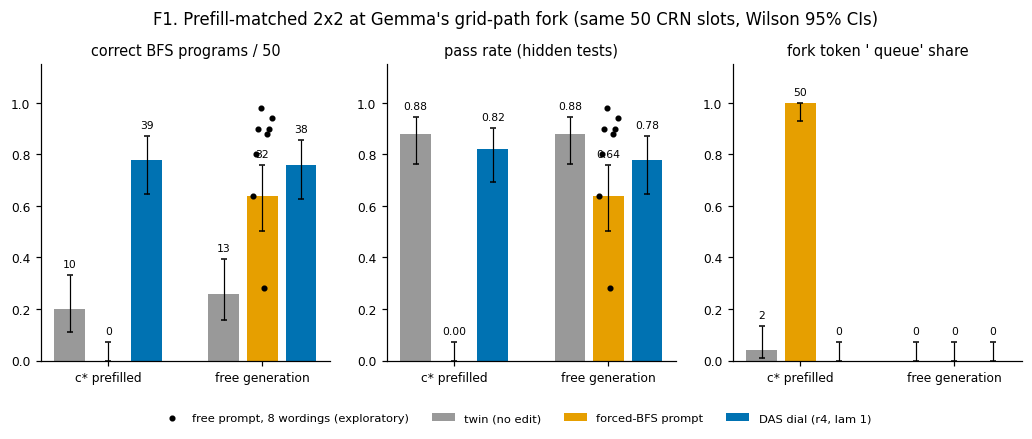

In [24]:
plt.rcParams.update({"font.size": 9, "axes.titlesize": 9.5, "axes.labelsize": 9, "legend.fontsize": 7.5,
                     "xtick.labelsize": 8, "ytick.labelsize": 8, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 110})
PAL = {"prompt": "#E69F00", "dial": "#0072B2", "twin": "#999999", "dim": "#D55E00", "rand": "#CC79A7",
       "dfs": "#009E73", "bfs": "#56B4E9"}
cells = A["cells"]
# outputs8 reads A["wording_extension"] (made in stage_analysis): the 8 free-generation forced-BFS wordings
we = {c: {"correct_bfs": cells[c]["correct_target"], "pass_rate": cells[c]["pass_rate"]}
      for c in ["G1c"] + [c for c in cells if c.startswith("G1e|")]}
# ---------------- F1: the 2x2 (prefilled vs free) x (prompt vs dial), twins beside   (src/outputs8.py)
fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.5))
groups = [("c* prefilled", ["P-twin", "G1a", "P-DAS-bfs"]), ("free generation", ["F-twin", "G1c", "F-DAS-r4-bfs-1.0"])]
labels_ = ["twin (no edit)", "forced-BFS prompt", "DAS dial (r4, lam 1)"]
cols = [PAL["twin"], PAL["prompt"], PAL["dial"]]
for ax, (metric, ttl) in zip(axes, (("correct", "correct BFS programs / 50"), ("pass", "pass rate (hidden tests)"),
                                    ("queue", "fork token ' queue' share"))):
    for gi, (gname, cl) in enumerate(groups):
        for j, c in enumerate(cl):
            s = cells.get(c, {})
            if not s.get("n"):
                continue
            n = s["n"]
            if metric == "correct":
                k = s["correct_target"]
            elif metric == "pass":
                k = s["pass"]
            else:
                k = round(s["queue_share"] * n)
            lo, hi = wilson(k, n)
            x = gi * 4 + j
            ax.bar(x, k / n, color=cols[j], width=0.8, label=labels_[j] if gi == 0 else None)
            ax.errorbar(x, k / n, yerr=[[max(k / n - lo, 0.0)], [max(hi - k / n, 0.0)]], color="k", lw=0.8, capsize=2)
            ax.text(x, hi + 0.03, f"{k}" if metric != "pass" else f"{k / n:.2f}", ha="center", fontsize=7)
    if we and metric in ("correct", "pass"):
        vals = [(v["correct_bfs"] / 50 if metric == "correct" else v["pass_rate"]) for v in we.values()]
        ax.scatter(np.full(len(vals), 5.0) + np.linspace(-0.25, 0.25, len(vals)), vals, s=9, color="k", zorder=4,
                   label="free prompt, 8 wordings (exploratory)" if metric == "correct" else None)
    ax.set_xticks([1, 5])
    ax.set_xticklabels([g for g, _ in groups])
    ax.set_ylim(0, 1.15)
    ax.set_title(ttl)
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.08))
fig.suptitle("F1. Prefill-matched 2x2 at Gemma's grid-path fork (same 50 CRN slots, Wilson 95% CIs)", y=1.02)
plt.show()

**Figure 2: slot by slot.** Each column is one CRN slot. Cells share the slot's random stream, so the paired McNemar
tests count only the slots where two rows disagree. On the right is the fork token that each cell's program actually
wrote at response index 32.

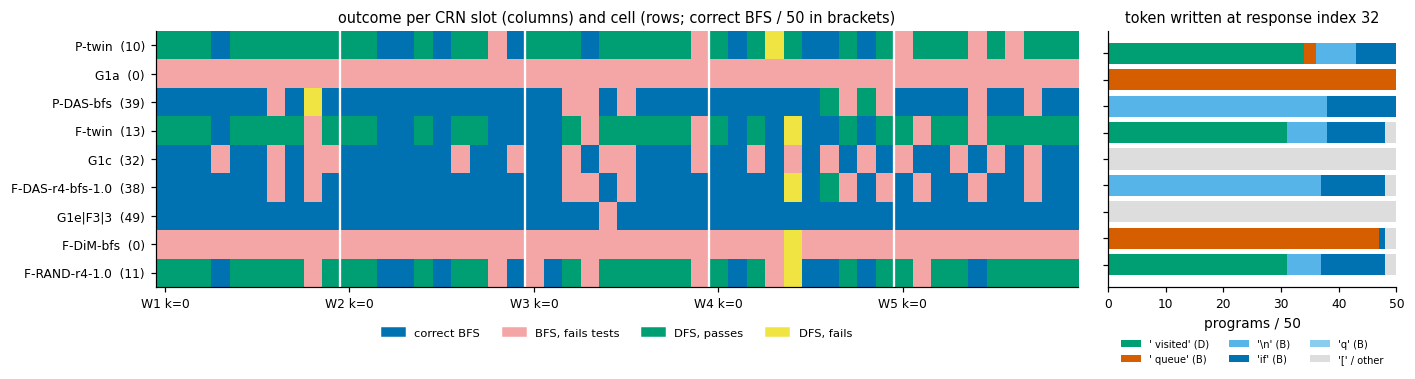

In [25]:
show = ["P-twin", "G1a", "P-DAS-bfs", "F-twin", "G1c", "F-DAS-r4-bfs-1.0", "G1e|F3|3", "F-DiM-bfs", "F-RAND-r4-1.0"]
M = np.zeros((len(show), len(C8.S50)))
for i, c in enumerate(show):
    for j, (w, k) in enumerate(C8.S50):
        r = lab[C8.rid(c, w, k)]
        M[i, j] = 3 if (r["label"] == "bfs" and r["passed"]) else 2 if r["label"] == "bfs" else 1 if r["passed"] else 0
from matplotlib.colors import ListedColormap
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw={"width_ratios": [3.2, 1]})
cmap = ListedColormap(["#F0E442", PAL["dfs"], "#F4A6A6", PAL["dial"]])
axes[0].imshow(M, aspect="auto", cmap=cmap, vmin=-0.5, vmax=3.5, interpolation="nearest")
axes[0].set_yticks(range(len(show)))
axes[0].set_yticklabels([f"{c}  ({int((M[i] == 3).sum())})" for i, c in enumerate(show)])
axes[0].set_xticks(range(0, 50, 10))
axes[0].set_xticklabels([f"{w} k=0" for w in TEMPLATE_IDS])
for x in range(10, 50, 10):
    axes[0].axvline(x - 0.5, color="w", lw=1.5)
from matplotlib.patches import Patch
axes[0].legend(handles=[Patch(color=cmap(3), label="correct BFS"), Patch(color=cmap(2), label="BFS, fails tests"),
                        Patch(color=cmap(1), label="DFS, passes"), Patch(color=cmap(0), label="DFS, fails")],
               ncol=4, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12), fontsize=7.5)
axes[0].set_title("outcome per CRN slot (columns) and cell (rows; correct BFS / 50 in brackets)")
FT = ["visited", "queue", "\n", "if", "q", "["]
names = {"visited": "' visited' (D)", "queue": "' queue' (B)", "\n": "'\\n' (B)", "if": "'if' (B)", "q": "'q' (B)", "[": "'[' / other"}
left = np.zeros(len(show))
fcol = {"visited": PAL["dfs"], "queue": PAL["dim"], "\n": PAL["bfs"], "if": PAL["dial"], "q": "#88CCEE", "[": "#DDDDDD"}
for t in FT:
    v = np.array([sum((lab[C8.rid(c, w, k)]["fork_token_str"] == t) if t != "[" else
                      (lab[C8.rid(c, w, k)]["fork_token_str"] not in FT[:-1]) for w, k in C8.S50) for c in show])
    axes[1].barh(range(len(show)), v, left=left, color=fcol[t], label=names[t])
    left += v
axes[1].set_yticks(range(len(show)))
axes[1].set_yticklabels([])
axes[1].invert_yaxis()
axes[1].set_xlabel("programs / 50")
axes[1].set_title("token written at response index 32")
axes[1].legend(frameon=False, fontsize=6.5, loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=3)
plt.tight_layout()
plt.show()

**Figure 3: the dial in activation space (block 17, residual stream).**
- **(a)** The plane of the first two DAS directions (R_1, R_2). The five twin fork states sit closer to the DFS
  target than to the BFS one. The DAS edit moves them onto the BFS target (λ = 1) or halfway there (λ = 0.5).
- **(b)** The plane spanned by the DAS BFS-minus-DFS direction and the part of the DiM direction orthogonal to it.
  The DiM edit has β matched to DAS's teacher-forced effect on the margin. It is about 7x longer than the DAS edit
  (about 1,380 vs 205 residual units), and about 80% of its squared length points outside span(R_4). Inside the
  subspace it overshoots the BFS target. In free generation it produced 0/50 passing programs.
- **(c)** The recorded teacher-forced fork margin m at p_f under each condition (GPU stage S3). DAS, DiM and the
  forced-BFS prompts all push m to about +10. DiM and the prompts get there through `' queue'` (p about 0.95), the
  token whose list-based BFS programs fail the wall case. The DAS edits keep p(`' queue'`) low (0.01-0.08, averaged over templates).
- **(d)** Principal cosines between the three seeds' rank-8 subspaces, computed live.

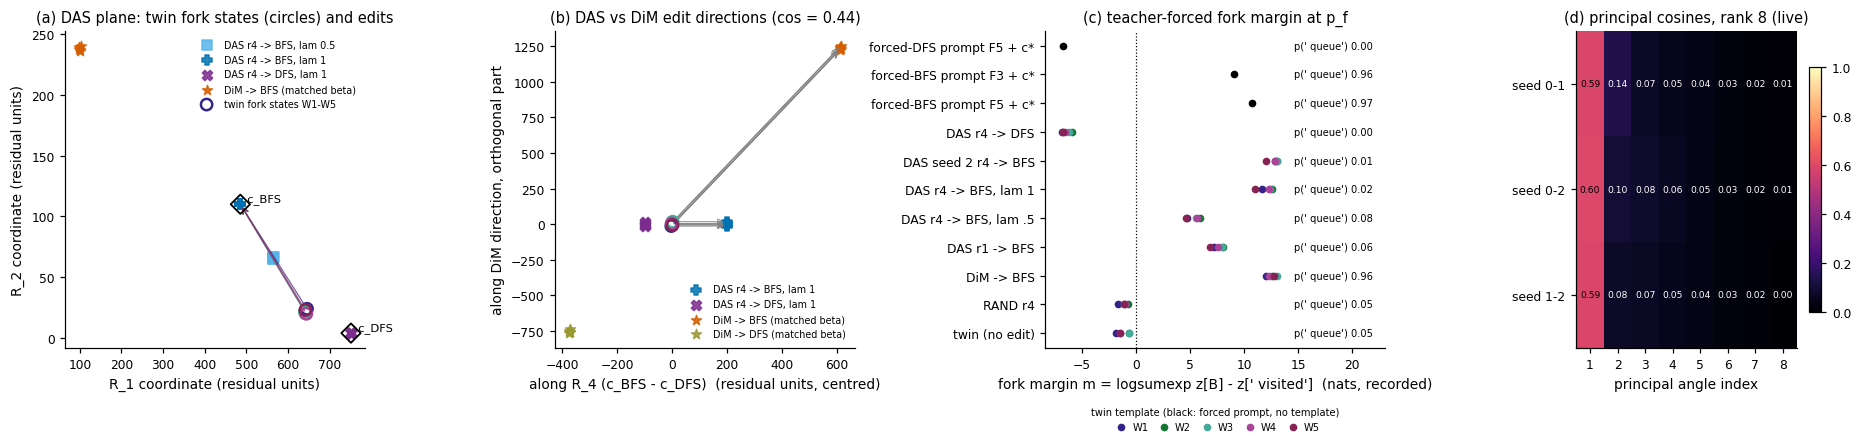

In [26]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4.2), gridspec_kw={"width_ratios": [1.1, 1.1, 1.25, 0.9]})
tcol = dict(zip(TEMPLATE_IDS, ["#332288", "#117733", "#44AA99", "#AA4499", "#882255"]))
# (a) DAS plane (R_1, R_2)
ax = axes[0]
B2 = R[0][:, :2]
for nm, mk, col in (("DAS r4 -> BFS, lam 0.5", "s", PAL["bfs"]), ("DAS r4 -> BFS, lam 1", "P", PAL["dial"]),
                    ("DAS r4 -> DFS, lam 1", "X", "#7B2D8E"), ("DiM -> BFS (matched beta)", "*", PAL["dim"])):
    pe = EDITED[nm] @ B2
    ax.scatter(pe[:, 0], pe[:, 1], marker=mk, s=45, color=col, alpha=0.85, label=nm, zorder=3)
pt = Htw @ B2
for i, w in enumerate(TEMPLATE_IDS):
    ax.scatter(pt[i, 0], pt[i, 1], s=55, facecolor="none", edgecolor=tcol[w], lw=1.6, zorder=4,
               label="twin fork states W1-W5" if i == 0 else None)
    ax.annotate("", xy=(EDITED["DAS r4 -> BFS, lam 1"] @ B2)[i], xytext=pt[i],
                arrowprops=dict(arrowstyle="->", color=tcol[w], lw=0.8, alpha=0.7))
for Y, mk in (("bfs", "D"), ("dfs", "D")):
    ax.scatter(c3[Y][0], c3[Y][1], marker=mk, s=80, facecolor="none", edgecolor="k", lw=1.2, zorder=5)
    ax.text(c3[Y][0], c3[Y][1], f"  c_{Y.upper()}", fontsize=7.5, va="bottom")
ax.set_xlabel("R_1 coordinate (residual units)")
ax.set_ylabel("R_2 coordinate (residual units)")
ax.set_title("(a) DAS plane: twin fork states (circles) and edits")
ax.legend(frameon=False, fontsize=6.3, loc="best")
# (b) plane of the DAS BFS-DFS direction and the orthogonal part of the DiM direction
ax = axes[1]
e1 = d_bfs / np.linalg.norm(d_bfs)
u_perp = u - (u @ e1) * e1
e2 = u_perp / np.linalg.norm(u_perp)
mu = Htw.mean(0)
P2 = lambda X: np.stack([(X - mu) @ e1, (X - mu) @ e2], 1)      # noqa: E731
for nm, mk, col in (("DAS r4 -> BFS, lam 1", "P", PAL["dial"]), ("DAS r4 -> DFS, lam 1", "X", "#7B2D8E"),
                    ("DiM -> BFS (matched beta)", "*", PAL["dim"]), ("DiM -> DFS (matched beta)", "*", "#999933")):
    pe = P2(EDITED[nm])
    ax.scatter(pe[:, 0], pe[:, 1], marker=mk, s=45, color=col, alpha=0.85, label=nm, zorder=3)
pt = P2(Htw)
for i, w in enumerate(TEMPLATE_IDS):
    ax.scatter(pt[i, 0], pt[i, 1], s=55, facecolor="none", edgecolor=tcol[w], lw=1.6, zorder=4)
    for nm in ("DAS r4 -> BFS, lam 1", "DiM -> BFS (matched beta)"):
        ax.annotate("", xy=P2(EDITED[nm])[i], xytext=pt[i], arrowprops=dict(arrowstyle="->", color="0.5", lw=0.6))
ax.set_xlabel("along R_4 (c_BFS - c_DFS)  (residual units, centred)")
ax.set_ylabel("along DiM direction, orthogonal part")
ax.set_title(f"(b) DAS vs DiM edit directions (cos = {float(u @ e1):.2f})")
ax.legend(frameon=False, fontsize=6.3, loc="best")
# (c) recorded teacher-forced fork margin m at p_f per condition (stage S3, GPU)
ax = axes[2]
conds = [("twin", "twin (no edit)"), ("RAND|r4|1.0", "RAND r4"), ("DiM|bfs|matched", "DiM -> BFS"),
         ("DAS|s0|r1|bfs|1.0", "DAS r1 -> BFS"), ("DAS|s0|r4|bfs|0.5", "DAS r4 -> BFS, lam .5"),
         ("DAS|s0|r4|bfs|1.0", "DAS r4 -> BFS, lam 1"), ("DAS|s2|r4|bfs|1.0", "DAS seed 2 r4 -> BFS"),
         ("DAS|s0|r4|dfs|1.0", "DAS r4 -> DFS"), ("forced|bfs|F5|3", "forced-BFS prompt F5 + c*"),
         ("forced|bfs|F3|3", "forced-BFS prompt F3 + c*"), ("forced|dfs|F5|3", "forced-DFS prompt F5 + c*")]
allm = [v["m"] for cnd, _ in conds for v in cond[cnd].values()]
for yi, (cnd, nm) in enumerate(conds):
    for w, v in cond[cnd].items():          # one dot per twin template; '-' = a forced prompt (no template)
        ax.scatter(v["m"], yi, color=tcol.get(w, "k"), s=16, zorder=3, label=w if yi == 0 else None)
    pq = np.mean([v["p_queue"] for v in cond[cnd].values()])
    ax.text(max(allm) + 1.5, yi, f"p(' queue') {pq:.2f}", fontsize=6.5, va="center")
ax.axvline(0, color="k", lw=0.8, ls=":")
ax.set_yticks(range(len(conds)))
ax.set_yticklabels([nm for _, nm in conds])
ax.set_xlim(min(allm) - 1.5, max(allm) + 10)
ax.set_xlabel("fork margin m = logsumexp z[B] - z[' visited']  (nats, recorded)")
ax.set_title("(c) teacher-forced fork margin at p_f")
ax.legend(frameon=False, fontsize=6.5, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=5, handletextpad=0.1,
          columnspacing=0.6, title="twin template (black: forced prompt, no template)", title_fontsize=6.5)
# (d) principal cosines across seeds, k = 8 (live)
ax = axes[3]
Mpc = np.array([ang["8"][p] for p in ("0-1", "0-2", "1-2")])
im = ax.imshow(Mpc, vmin=0, vmax=1, cmap="magma", aspect="auto")
for i in range(3):
    for j in range(8):
        ax.text(j, i, f"{Mpc[i, j]:.2f}", ha="center", va="center", fontsize=6, color="w" if Mpc[i, j] < 0.5 else "k")
ax.set_yticks(range(3))
ax.set_yticklabels(["seed 0-1", "seed 0-2", "seed 1-2"])
ax.set_xticks(range(8))
ax.set_xticklabels([str(i + 1) for i in range(8)])
ax.set_xlabel("principal angle index")
ax.set_title("(d) principal cosines, rank 8 (live)")
fig.colorbar(im, ax=ax, fraction=0.05)
plt.tight_layout()
plt.show()

### Summary: live replay against the recorded artifact

In [27]:
REC = META["recorded"]
rows = [
    ("S0 checker gate: mutants rejected", f"{res_gate['checker_mutants']['n_rejected']}/5", "5/5"),
    (f"decision rule == commit #2 ({len(slots)} slots)", f"{same}/{len(slots)}", f"{len(slots)}/{len(slots)}"),
    ("F-DAS-r4-bfs-1.0 commit #2 prediction", f"{preds['F-DAS-r4-bfs-1.0']['total']:.1f} ({len(SLOTS)} slots)",
     f"{REC['commit2_predictions']['F-DAS-r4-bfs-1.0']['total']:.1f} (50 slots)"),
]
for c in CELLS:
    v = out["cells"][c]
    rows.append((f"label replay {c}: correct BFS", f"{v['correct_independent']}/{v['n']}",
                 f"{v['correct_labeller']}/{v['n']} (frozen labeller, same slots)"))
rows += [
    ("G1a correct BFS (P1: >= 40)", f"{A['cells']['G1a']['correct_target']}/50", f"{REC['cells']['G1a']['correct_target']}/50"),
    ("P1b dial vs prompt, prefilled: p", f"{T['dial_vs_prompt_prefilled_P1b']['p_two_sided']:.2e}",
     f"{REC['tests']['dial_vs_prompt_prefilled_P1b']['p_two_sided']:.2e}"),
    ("P2 free dial vs free twin: p", f"{S['P2']['p_vs_free_twin']:.2e}", f"{REC['scorecard']['P2']['p_vs_free_twin']:.2e}"),
    ("free dial vs free prompt G1c: p", f"{T['dial_vs_prompt_free']['p_two_sided']:.3f}",
     f"{REC['tests']['dial_vs_prompt_free']['p_two_sided']:.3f}"),
    ("interaction (prefilled - free)", f"{T['interaction_slot_bootstrap']['interaction']:.2f}",
     f"{REC['interaction_slot_bootstrap']['interaction']:.2f}"),
    ("principal cosines, max |diff|", f"{dmax:.1e}", "0"),
]
w0 = max(len(r[0]) for r in rows) + 2
print(f"{'quantity':{w0}s} {'live (this notebook)':>24s}   recorded")
for r in rows:
    print(f"{r[0]:{w0}s} {r[1]:>24s}   {r[2]}")

quantity                                         live (this notebook)   recorded
S0 checker gate: mutants rejected                                 5/5   5/5
decision rule == commit #2 (50 slots)                           50/50   50/50
F-DAS-r4-bfs-1.0 commit #2 prediction                 37.0 (50 slots)   37.0 (50 slots)
label replay P-twin: correct BFS                                10/50   10/50 (frozen labeller, same slots)
label replay G1a: correct BFS                                    0/50   0/50 (frozen labeller, same slots)
label replay P-DAS-bfs: correct BFS                             39/50   39/50 (frozen labeller, same slots)
label replay F-twin: correct BFS                                13/50   13/50 (frozen labeller, same slots)
label replay G1c: correct BFS                                   32/50   32/50 (frozen labeller, same slots)
label replay F-DAS-r4-bfs-1.0: correct BFS                      38/50   38/50 (frozen labeller, same slots)
label replay F-DiM-bfs: correc